# Exploratory data analysis: GDP per capita and electricity access

COMP0173 AI for Sustainable Development<br>
Thursday 15 October 2026, 11:00–13:00

## Overview

In 2015 the member states of the United Nations agreed the Sustainable Development Goals. Target 7.1 reads: "By 2030, ensure universal access to affordable, reliable and modern energy services". Progress towards it is measured by indicator 7.1.1, the "Proportion of population with access to electricity". Between 2000 and 2023 the number of people without electricity at home fell from about 1.3 billion to 677 million, and if current trends continue, 645 million people will still be without it in 2030.

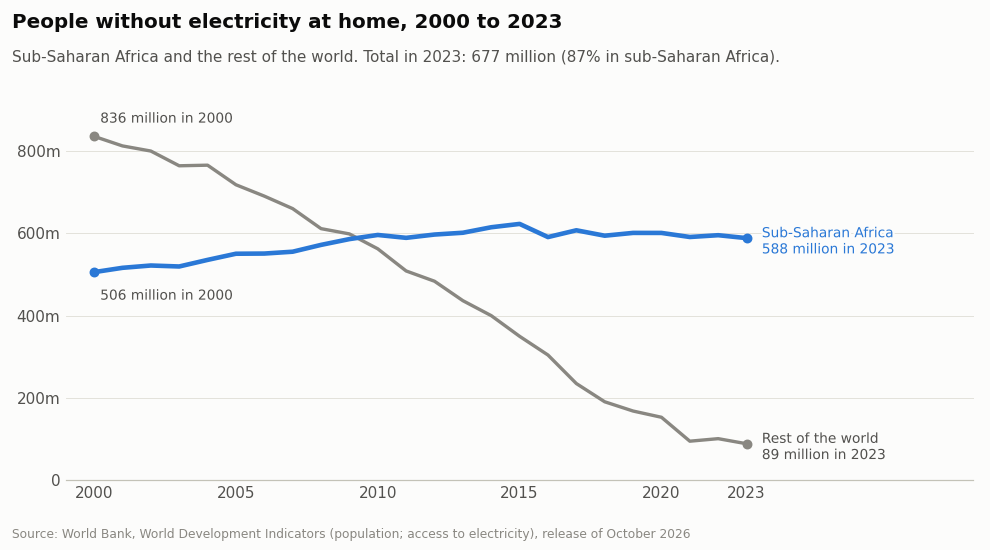

Electricity access is one measure used to track progress towards Sustainable Development Goal 7. We will investigate whether a country's GDP per capita provides a useful guide to the share of its population with access to electricity. By the end, you will give a short answer supported by a plot, a numerical comparison and a limitation of the evidence.

**The question for this lab:** How much does GDP per capita tell us about a country's access to electricity, and where does it fall short?

GDP per capita is gross domestic product divided by population: a measure of economic output per person. It is not a direct measure of household income or wealth.

<small>Sources: United Nations, [Transforming our world: the 2030 Agenda for Sustainable Development](https://sdgs.un.org/2030agenda) and [Goal 7](https://sdgs.un.org/goals/goal7); World Bank, [World Development Indicators](https://databank.worldbank.org/source/world-development-indicators) (population and access to electricity, release of October 2026); World Bank and partners, [*Tracking SDG 7: The Energy Progress Report 2025*](https://www.worldbank.org/en/topic/energy/publication/tracking-sdg-7-the-energy-progress-report-2025).</small>

## Before you start

### Learning outcomes

By the end of this lab, you should be able to:
- inspect and understand an unfamiliar dataset
- identify missing data and values that need investigation
- use summary statistics and visualisations to explore distributions
- examine and interpret relationships between variables
- explain how EDA informs analysis and helps avoid misleading conclusions

### How to work through this lab

Save your own copy first with *File → Save a copy in Drive*, or your answers will be lost when you close the tab.

- Read the text and run the code cells in order. Cells that only need running start with `# Run this cell`.
- Each task is marked ✏️ and set off by a grey bar on its left, with a label such as **Question 3.2**, numbered after the section it belongs to.
- Write code answers in the code cell under the question, replacing each `___`. Write other answers on the line marked ✍️ under the question: double-click it to edit, and press *Shift + Enter* when you have finished.
- When a question asks you to predict something, commit to an answer before you run the next cell.
- **Hint**, **Pointers** and **Key points** stay closed until you open them.

Work with the person next to you, and keep most written answers to one or two sentences.

### Setup

Run the two cells below. The first writes the lab's data files and a small helper file with its plotting style and the models it fits (in Colab it is collapsed, so you only see its title). The second loads the libraries we will use.

In [3]:
# @title Set up the lab files { display-mode: "form" }
# Writes the lab's helper module and data files, then checks each file's fingerprint.
import base64, gzip, hashlib
from pathlib import Path

LAB_FILES = {
    "eda_helpers.py": ("820c123a7e407f8e35edca5407fabd944de7ab48b0ddabf742dcea7b307030be",
        "H4sIAAAAAAAC/9U82XLcRpLv/RW1sB0C7CbcB28ZE0FLlKywrhWlOYLLaBaAajZMNIAB0GL3cPk6zxv7KfMJ8ynzJZtHVQHog9ZcDys7yG5UVVZWVt6ZoOM4P6m0UGUlpnkp6pkSz969eT8YHo2FWhZpXso6L1cilrUUMpPpqkoqkcrQ7/Uu6kWssroScZ49qUWmVCzqXJRKwu8ZTJsmqfLFqxomKIS/KMUfF4mqxS95WJ32ekNfRDMV3VYwXda0eZJVtUxTgJQmYSnLBBbOZR3NaPQz4JnkWUVfAAlxJ+GzqmqYf5fUs6e9kS9mMosrkS9qRhqRgK9ZuhJyWquSt0yyGwSSlOLip7O90cEhzMtuVFmUSVY/7Y19Uama9wEi1DXOr+pVqoAIsSjK/HMSA9jZGu2myc2iVNXT3r4PnwEAzq6iHJ4ZnJ/AgfJYpVVfVHlz8CyvVZjntyKSmYjyLALKAu0VYE7jeBa/5zhOL5kXeVnDMasZ0Mh8XZQpfPNL9ccF0MM8vZNlBqhXvWmZzwU/xGlzVUuijp73Xka38ka9zesX+SKLz8syL/uG3Ly4kDXu16yoZz2zDdwQUgmH4ULmRbo54ON6NZ2qCKlSiUJtm7PCTzSc2jNki3mxwmdZYR4VQFbJYGLzrFIyzMsMH1ZZZZ/Wsq6Y3r4sEhqd84Gq21QBeXwanVQqBdTgtOaAP7/I07jX+0r8bqZKZe8A+PKzqnzxOo+AT1ciqUVS2dHvgRPSWJVPBd6gKBZhmlQzFffFsxzuHqDF+V2W5hI4VEngauROQei8Pvtx8uPZxfnk04fXIAYgSM/PPp5Nnr/6gCwwTcoKLrlSfq8zMRCOI8RXyK0oe4jHy6T+aRGKUt4JnOEWSZaxZEpgrPk8qT1xN1OZFSLA3yLas5sGdMWug8dyvF7v2U/nz36++PTmAkbuewL+OdUCyJtkMkzVRGWqvFn5UfXZORXO+FCGJwfTKNwP49EoPB5Oh4OT8fTweBzHSh2E0XA8Ph4Owngajk6iSIZHh6OTOI6ik0M1jqLY6fMOd3mZxpNQZreTCBizRn1g9oDJ0WAwDeOj/cF4cHhyOJTDsTw8HB+fjKP96GA0CEdq/3h8FA6j6f6JHByEKjyOj6LBfhQPR2OzBx6wkotyUfm1hnwc7R+djKKxiocHo/FxKAdHsYzhTEdHxzKOjk7io5Eaq+F4tA/Kbj8+joZSHYyO90+OjgfT4y3Yl+oGFZfB/SAeRuPxYXx8EKmjGKAOxkMVx9Pjk+k0Hp2owXBwdAxIHkyP48PB0XQ0nh7Lg0EUHkSj6ckJ7vCAvPnbX1GIp+Jlnt8AixH79cW7qM5D0IGjwejQ7308v/h4/nzy2/MPF6/evW1dLMsXIjryRz5QSjgkhfxkyE8auaUb94cDf4DPtSDiw4E/HPsjQ44qShjE0B8eMgx4dJvUeySIPHLoD2mgkVsN6ACha/RwW4J04I/2ecE8qSrQdFnO0w9oW6IRHB0tT5mnKLcfgVCVnCsQBXos0zu5Ap2lpKYiDYL5ym783o+vP52jiH01knAdhw7u/pU2I+fPz05pAWj3ElSH1ZbvPpy9fcnLVAgcv88CepsUBdyKXZZJUCR20dl/fjqjJcNQTo+k2QkRKWNxU+aLoo/iH4NclwptGRgWjTvcrEKT2Xv54fwPBOT45PjoeKiBgDGp1bI+FQo2W9HJ2OwkFZptMlt5tKh6H86f0+p4MA7HIa1GHDKh0ByIaSpv+mZPZC5EDwDz/r1Xb3/uC/gxGfXFm08fNaxBiP/hBX11MDoY7iv6qPEDhF897wtUZq9fvT3vi4tPH16cPdO0G6pBfELTo3E0Co/o4zSC/0Kn1+vFaiom1l1wC7Zg3imxSF2u+AP+K1W9AMOgSW1n0rhaRqrYbv82ADhgoxsHxeJA/sTEuCauxgAs9UUtV6ICBZ/VrHBbF0A+DTgK5GSBDhVFniY1XizNTNhngvvx0eQjwLhMpijWIKTFqXDbR/f6AnQ6+iDAJIiiWJNsH0DPATWRdGnmif8IRP1A8GFIb9EcPE0ycFwCcTkFbrgvHk7FKl+A5wGMe48/H/q7FI+45y8PjsHLxQV9PcdDJPV2Brkru63xWnz84NrHRNaLHMSz8Q3jBFyKki3omofIfuo6Yr5wugDPm0upZvkiBX+tTtJUlIusL0LwIsGFVHfohYTo6c3hTvWmVZrczEAR+f+VOeI74cAv/5c8yVwim9fv7AM0j8Dh+KzSYNSMeJqJblQ9QTvkZqB9Gg76wIxHNEZ/g5wwtuR4NOvf9q1bgccA5mF3Aa4UnXIgcY8gfiQPNVVPqra3i/afeBgoRBwq6mSuyDvF29YCz76/An6VEZyZpcz4RG0muCuTugYWhmv3zTkMg+HpBEuRsP5ES85kAjv8rFYkf+7U+ZTdZnCw5qDiHkH8R/ngi7PPMknR9TgV90/64gmT3kL1HhyWcCJZ0DhT3xMWFqO8phm+WiZVbaW3Ndp2t047V8rovgC0OnoD8L5HkA9IWG2WSF0bKs3Ql83tlZGXBkqaY4fY13jjP4O0P7+Nk9IlHCf5bfCxXKhmVtf19+ErKCyQjs8KUWnj//A9OalExAfQp4imZ0ihAwq/mkmIh1yiCsZyk3AF8uN6nj9Tyzi5gT1cUhyW1pcI72r9Hn8r04WyFKEtkSJI01ozYiOloAYxMoBrrW6Buz+eiVABBymyXkm2QHOsCaO1cUEBCEkP2MUJAJlQgNZSwGdFAQq1ibvWIjmQI+Z3pnyfg7VZfidq5CuOL0g5a+G3unhD5/fYVr6n2fVdvherKJmDwBq1gUoX4+J8CuFgAhYhmSYR0kJSzFEtIBaA7Ub+wdH++ORYfTfYZ+kpYh98+0le4DzwxpMKUFr5U+CcegIUAkOChvH+1B9NHxyfnzA+EAbR2kKmCkTSvUR3BnxA8k/6Al2OK54JEZtfRu9lKeeVvyiASZR7b6/TYfr48KtK/qTAwXKP+2LfPwC7Y8biIoHnw+EAfTdQ9PC49WwTlIwUOmAlTNBGHxbKJXho24cMzG2jLejALL7GkVBB/8Q389FDaebSZuS6tMbReWmNtEHR0zqpgTHMU/9gHR6No6rG20JPNFVTup9mdOtuNFLIGJ4fr8NU8Y1d1LhKGkuwNHdJXM9gbOBvLK0KtER+nRcw/kKmlep3R0q0YHZsbfVNmSBCqGxgGX6zpGTHjZ91cTg0O0hQVkDC/M6AaKAv6yS6tbDIWYRVq61Pee7We1rtGlrfaS5/AWOkr21gV649Xjt9UebFJFpFKY6igNDn0qWtgq2y1AJBLkCHNIgxP53L8hY1B+17TFGQBPksm5uutnJ3gT5jhx0a+UjVjcpifwoSrIjzWjf6YLwMMPoQ5LsgR+CHIceBkV+E9Cl4m2dk8xdlxF8aNfoSAxWptSR8mIEiw5NwFIGRms5uAXx0QECRWrgcp2i45E9aJTpTyHxgmlGu0QFCioB3in6x610O2R8E3oUpQ7EnXGDwAzRUFjYIqAKWOzjwwKozOFoTgpoHfzCAsbEdoZWMBq+jqbh3jcNgQMDbqV0M5QIXmISB9MWwjzh4XjMddArgMhjCjSJeEJuO7C6WsDMZGOH/DB9RBPsC9ROeMhiO+csdLQogZp4nYZ7GMIf5CxjZGmZz3sbAbkdj/6CFhln0q5gMWltORs2mRKrdW8Kv4/Z2NH1jMyZie79jsx0JeMeiwxaaUaN8XkCY6377LRwDrfbk9q4VVyWx2gtXexX8xlQgXOeWkFq4eSnByfUE4sOBCgTfzXAI7oknSANaniTRcAkO4JwsMVIJMBnpa0QqF/hhhGNkCwMX6cemsIMsQSM4ZILpKlznApMA6IAAIvaqjQ7Zyg+G7QCTNqAzk4KwUFgfPQKjIXJftA+oSU5q1JXLvoD/V32K7DucATHGMgDtHq+CfTzsLQRnN1VzK68RgADFAaEsRhXgsCqMFPomVzCTac4pb8V5A9AcEFigi4nulsjhZkQOoyVDaNwtufRlRr6SchkvF5EEmi9X+D1w4yUi5jHaUZ6XcRU4+XSKaVEG1ubBE3Mw+tmN00zIMNG56uCyUD6e4KIu81vlWpUekAiXCnMzWRxoVexdtWjTw/TT3r/uH0B7QykxzgQlNoXLaa0aNlU2HS2jSFUVHnQxh0jWofx2mURJvZrw2KSIagfFBOBuGXYEBO6O+QybUWa7ibDBlW0XLoD4FIUP0K8eDgY+QAXGIA8buQIeOUBaiHASLAHA128oNcAuOGd3V2g6VhJuDw00AgqVrBkQEt5p7ghsSg1xBip2skVTjDpjEa5A3CXEvtUfF6BBqmYt3LnEDJwjmjQfPyf+1IjRyWQIvIgYimhR6+MwoGovWpSfLR4Qhuc3CSIr6LnBQmfiIZLCwo8LtrOUBBsiAlxRg6vwldj8dzdLIA4IFRaw6vwOCQH0RBOKyODvDMklbrCeVuAxYZv5v5jJ3rx7fv4ak8Fu9/K0/2J+W3r2G7IYR2PCrOhSHNWoiI+ko4HumnVaPLfXYVfktmtafN2oZuAVWgxj7i5u3srnzlpQr4EQfJ83rNYie9aVNlFgEoAaHpwySiVg+4Kuu4k3zf1T4prdIyznad4yIoknkdmKEWDusxw5BX5fUNhLaNHpOf2HZAXvKKknE7dS6bTP6/tmSdXnbbuHZUx0yoVvdlsSoxOr85r5AtgrVKTR4b7uefFDKzuBWPjN7vSV1wYgWVXtmjFPo7aJWBCsaYht92Af/R4AV3NfxvEkyjGLmWkWu+ygcuWDZKwK5VKQ7KFTUtkFgQPLW4fooGL4uIvFVM6TdMV702csQv2YZPk8kanrddN8iAjgsEhrXvDy9RuNY1corsB5ggP3xe/7eoOAf3kQZ9ctqOisnj6+x7vXF9v3AOgGnGUizYxtHuqyTPsev+R6MEVxoTAb66LahyNBGKCWAcsXffb+rVeoT0S58RZtfHPS33uPHG/7lbdBNp+/JUOwG1ZHLX4BQD9Kk8JdwPQS/PCB19tJ2KwAgsiylCvXrva2EtpEepqsG+ohaJS11VugxkjMtdoyabEyv0PJ14qYzI9GDOa74IIIS2LwiSbMSp5V2Hou68gd2CC+788/PDt/+/Hs5fnk2bvXn95wIdLoWtDo4M9hvwZ+LBXsRPVmsq3Opu+mY+UtVgAhgW+QTTS81vMGLJex/37oxvps24HHdsHavjetedC3SUEFtgvoIvjKUJOtRHORz7HojzdZzWWasmNEHRV4jTz5mr200WBAjtpoMBpsumFt+8ua470qsSNF3ljTxN4NuEDG4RNVJFPVdLVIEc0wAOMNh7zfyYl/BC5QfltxKwagyS5+xZ0UvnhHEYDZBLmMGiU0Zk/A77zLzFahiiTO4E4eqq7YklDINYoZOOfApOyuJnPwm0IFIZLKRNNQ0ClT0LFQTBtXZJNDaSZZblurijA7MzFf24UEO6VK5gUEo0kKwZvrJDdZjkwmPlWq/B3P8TCL3M5HoP+A1hsEWgyPDmAMHAeOeS18zMKh6gN3oVQp3reLaf5AM8kycP6gZAkbrQITDcDvwDnPIJpccQQ5uStlEQwPd7Ep/QOejgPjBHLkH2DWEW4Ps/fB0B+byApL0X3RBEvDRwFjVhfD5iq4d4j+WNzni0DvEj8sdRrxgbUkZR5tQFy5zj0ewtQ1KMo78A+wwhEHo+4Sl5KCENiBeVw1H5cUAQcO0sl8bLIhhMtph+QEa5Umc0oXDQcjnSMi3sQStuakrnw4DTjOQzlt9sZWH2wbszzuNKjr1Hm1KDgJMKUzw3U+9Dvi3OcgHHlEFCRKDNq9J4gPHnHC0B94W2BzkmMi41/A/XNnVQE3E1BW9858Hh7owhpmRWb5HToXvU9vX31sNZDcxMUE9p6ALUxqiYnwl8/fMzb0RLhgg0osjH+6+NozfR1blDasPGOvGc1SMy7cb1Cii7xYpJRst0CKMpnLcmW0aReL9zwoeLCD0O3vZvQd+/la4LaajA5WNENMF6h7UJPqubsx3GFtAOgHM6KVK+qsvIagcZpg6KixRj9oMaeCEGzSHNzuNIlVVqFo44ntU6GfCrdQOeghOu3t/K9/8bhTBhvLOPD7wkvcEW3BvPPWRRkr+8/czk7bDYueEfkN0bu7fQml9Wba4n85Gc0eEM9PNikFT8UmtXDuoxTAZcVuKjQ7bseSlm/D9IEEdPLu7es/PHa/LaFsycLue17j8C+65K6cPXazO6DvvlRasEtUdt/tmjgQub6ijBpWptGmVKSUi00fSKc20VsT1WI6TZZPwV0pIUJsJcpiMM9gw3uoHCYaHEguqcy+YKkDL8BckPYceKatxpoSOjmGp3qUC+/t1Mg2K+v+a7xhD0zvs3dv3pyhisCCGNpOVfovFln0gsrO6Nakch7GUnzGhEJfTE4FIE5fTvv+YPrgaA8nuuWMc2VL38NBH4xY2+PlZMqEuwCNy8vf1lxe3Urbyr1QMhmzKnkI3tVnyYk9kAlK2a2JpsBapc4D4kUn2V4l0VUTH/76lyYBhW5sq1mZj2/ahTtU6LXcMgjinoM39gIrc+79ptBBaHej8jlZVx0Kr0+68udJ5nqPulCP/tsJVi4BrBhD7Nnyqy636bQrOAqgCiPDgcuz1md4TQlFLtfLJrZgQq0Dx9pXkktfFz93HV2nKDYzG1WAZajG2/RslpCaqEyA2TeNniByf4JoW/eC656zvrhsl3D7AssoVy3fHRAkh3r7ifUmNgzGWV67uLDYUl1g59K2xLjAY6iTywmnrOMOp3vU1+E5llxyOUOv2qXc0XZfm1xyKjVjm0vg7O01y9FlXpIf6OItNwNLlAEaprK4bi3Bi/lV+f66K+DtvVzjVT/i/vVJIgknr+V873L7vG4ozdXrqZkubyS22qwJODrIwxNgDCR0qjLNRW26cgHdTfMocCgjI1DXKwybwjBfTup8IrNoBuR2se9D7IEjfEw1D6q4B1RvJ+VGTQ9cglliogPVbGlS3lyM2vSfUelBuIclzQmVLXfpu2fozbPCoyFsa2qVLnjzwTdYu7FljG/s+yllfle1cjpWt1GMgJ2exJSn+P6B67pzy9hML/EbhOaJ/xabQz+IgeeBuM9dz7MGCdBHuevK3ENva4qLUejTusBpn0nTRQz28Cy2yEA2gvvq4RfMWMjGTJgHgWM+OfgQJ+OjG3YImHnAGdSrsXykBxuK/5gvbRKl3JzJZqObPsFrzZ7qM+o3PXj2k4onUTZtDmeUmb2EcKWPA/fAOT3q+w5XLj/2Ls32V768uXEvHQJF3e8ECVSwX4ExmpA8QlCsH3+ZYj7hQjZPzkus9QUNTpxftH1lIBIbiYZVwFMx5WAw7TOkgH4aheXczYAXME4HOk3RWaoC3Z0kl4FcttrXQO6Lf3wjLorT8cYotC3opEo/kyodrNW5O5q0ozk5XeCygKIeod08NCONPicl09ANNMoly8ITuq4nV6B2OtUsAnK1VW0azjzVfgz6N0m2qFr5ZF1UclveKSsZbzOToY/B+QPdHoIZkqE5JmkM7d3BKSu0AnDZcNQYPDH7aDKVEb4W6AJAeogeDpKXv52B3rMbUtPI3rAvhv4Afjp/+/P/tHw0sFEQK9QKHU8LPiA8uJmEO9R+tZuk1bxi9my25O0WcIZmP/G3P//vrj2/rIGltWVLlbd0m+UBrbCw6JFnaiLriZxgLtIoq1Ai61PrQ2W0VMWPJ/oC8bMhW5Zi0m4tm7/LOZRpamB8h1+0IZoLl3MV9G4IsgrtRsqXW8GSLEoXYI1gDfcbd8oFaEwanPqs4rDTGVu+4jjh5AQqOe5cpXflcHszWHmoH8l1RgeIiws3XCJntdUoW52D/h0q2muL53Vn1z27K5YtkuatGOH8YJf8RnwnfpgrWS1KNQdh+Y2j09Vc5qUlosKuFN3mrivyWtryUr+pyheBxENvo5s/xpsGFJjo7X7+dhOOc29xegCc7jkIxC447bzSOtAdd+ByeQ+UNLQrOG84hfvUjdxswoGESUysjfrH8s6puKSelPt1pMRm9Kh58MG+EdJiguYQzU6XlrswPODFLAHoZwAaD9Ypp1lwY0uQONypAWL8gnavWc2VslYZi5jtO15vmF+XkBriMr9g68L2kuueBr3mvHjW0OogRPsAYE6ZFVvlWDzZpT3yvQPMC0HchvPO++wO2eA+gAl4n4d1hkeA+uMlT+Fb0t5Bkhkd8bDuSzWRJuLp+R+16rH4cZWu61w+Uhl81Y6EuU6EIofsElONn1I0VjrYomfc/1IqJUwbfJFCdFutlwYb5+9es+o2OnaLXVX38r0dBG6xnMnVbDqixtnEO4SrloWLffTjdh/9Gvk6hMMERasr0WZs8TUkWSacg4NdtYWWUZlX1TY33NTLOhkMiFyoUqqV31C/osiOZuMeo6ojZfVUDFpvMTIMeu8+wy4qjN1wG9uMol+AZ4sJMNFvaPWndPzZroJrl7ItHdYkin1I47IE22P43rrQunbFXrOLB7IiRjq00C3B9eZ889FHGmAMsr5K8xy2yto9v2dY+pbpPf1fLZtjo4uKg0HrNRNNPn5NEq5VWkvdFBmxvHkn+fWXpkvMrVW2h6+MC2KOPXDcUSmis6/v/bxdHUrajh9EIGajbtsZ91Bm1KENRm5mW/U4qCCwH3RoQmFqB398F3HdleSWpTRtjtNvtSxxbNnEkXRcDkRPDr7RXMVv1+DLNXPsfWrHd3eYCGiCVV/QK3n6aItKVfZlM343V2X8QqxGS9wkn+HRNV7LtbHnSWn+7AI2YIXKtBTHT7kqrdmf7lKXfVEmCb+F/msTGsAcEQNi47pIdWWBW7hMuBaXeZFJF0Ir8LKDy6aF4Vvb1+JtiFCnySOT2c72GaJzCQ4Hv0SJF0V/o8DNJlWRJnVFvdzVbDGdQlDLb22Adxvn8wn16Ad4VpAInOuu9/1YQQaM2h0bfoLxC217taV7Y6O9Rc8H/K52q4fWJM+v8wm9W67FlJkQhLuh0Z7JX2p6wiIZmpeumM+C9SniB+C9HbameaNC8d+56HA2Gl/s6HVpUKsTCCXab3fodZbHu2su6fnV9qVb+0wRAKVcmkNTqsUfHJicin6VQ5sslg39hqK5FeMX3tPoA74XCR6TfjHS9uJhfTzG3qogD39RkbVxcZ6mspxgGpDawPFD4Cyd9Q5vSqAPB5Rhwzn0Ji+t5b9oMqaObmrv+HqIKX1r9Sl4xreJKXc5xh/DyYA+86/hQH8dmO/0gQ1FmkNwliBnQICHr4ss02TOrzQTGtiAtXSYBnrGimZ43c1rFiTqAKVnACDNxQ+t9Hbt4ddZwhtXbDwDmz61y7bt26QJWovdBjSOcL7g6/v6tK/fj27Q0RqCQ5GgKblyuWx34rST4GU3n356jyLanrhWeml5YBU1keiigENplO4bQhecwyfb183DXi+v+02LKzdJw6zNgk1cSnAc8Y/d5IU2fde49TXYC9D0UlOE3n3uGD0Cfk1Njtfmj+XoQNQ00wISG68iyyVaUzxGowQn/0ThYmkrFVYHUY3iuJull2kxk8HAP4JQyL7tFTgZ4OF4u8tGS6oTpUDSVploaepCovnOBZ1RU9BZL4iQ07peFEFCbymJcPqM323bURJZXvW3aPltdZBWWm3kY5aNkhIUij5S22heeGz3Ej1W3dA8/Uj9wHb1LLlrU/N1c8KuKtR2qdOG2xW05dYqAgXv/H5R9xUcuexmsNdS1/wqNHY+dYQuXOnEzIb0vae/mRTV6NFydtCA2CqNrYQMX43xJVeq+h6CBY6X/H9eVkwuueXir1vpPYuq2Stcbe61VdiaxO9uKTveKWXd60Qh0RUtw60mI3KJeUQjECG+YoT5Yv22Ff1FkPtw9eB4V2ut0ZwAYXTDle1nBivvIdfRbp0V64ekxDGCAT5oHZcerakWg3Nz7F1phw1qbMrhF3FyS1h3Z8+HO+TyEUZ1Ter63yWj6yKYL+pJPp1gCDZpuWb/QBT4Xr/k0Wnn0/0hGwYLOzv59RDb1kpRoMt/jScF/+mawo9rCoBMMGiiNinYl4UbT24yawQ5m/CUmc/+5QlrBnUNEPaO8I+oYLoCM91CzYtax/jvTECt74Nvif5KQzfloAHt5VMOX1uj7Dd37O2i+v8aJzHmjwdKPOfvjpRwulmK2HNAtD1s6myxNW4yYY4B3/s/tZjjzNpRAAA="),
    "data/datasaurus.tsv": ("..."),
    "data/sustainable_energy.csv": ("..."),
    "data/world_bank_countries.csv": ("cc9c00fbd740306961a13a663893c4c520b2e4837b1cf49a05beb8d7c04cd123",
        "H4sIAAAAAAAC/8WdW1McV7at3+tXVOhhb3dEOiNz3dd54yYkcxFNgWTrpSOBalRtqGIXYG/5159vrAQJ5CooZJ847m41wlDrknOOOeY1J9czW/1+8q9pdzmu5uPzyWxaTaans8vxv87ns9ur6mp2dXvR3fD9f5mmzVV3ejq+vubrpvn69cPvG1udn13962o8/9dpdzW56fp/X753dVX+Mlhb/1CtzW9PumqXj54O1y7H88lpN/yv4UY3n5ycjLvpsHozOf807PdStU02ja2bKrd15G8NX/Z/2iZ4V7vkW2O9zbGyyfON2IaYTGqTG6y93qrW/l0+f6u7vhnPp8NuejYczW5vPvGXau38nIN3N+Prh1+G6LNv2pS1Uq5zG40P1jqTUq6cq21uUmi8tTa4yjd14BdaH7NjK65qfZPqxrbeOJ+SNtW4mh9O/Jcb0qa22dT5p246ub7pptWrvcnZ2cW47LAa7s/mN5+G/aar4YOf44YOul/Ll6+q3dnv9/djY/KhNS2b5TKqHLml5GtbuRzq0BjfOOOTr/jD6rKsNTanGNnH4d3lLLmH8g8/9uH+Dj+Mv97hxnh6M+8ulvyqC8YbY1LQY3K1CSnZ6ELbBGcr39YmZf7eOG6k9ZWPNf8i6idSE12sjOHeXWu899ZxvZV3PP2QYrYuR+fZ/Pa7am16PrvoqtHtyY+j7lM3547uNqr7Gc+Hl/3F3l+UsZHnaNiSYUuV83XQXlqupol10tqm5ZmaKgXuM/hsm9Qap7vaXa/WLk54FF21dTufXY0lsP0VDNeu+e7x1dWfVkRsYmr0ZDLHeSS7oQl8C0myrW0bg2AH59ia8S5yWOcHa/ubnPBsNp8vW/KhlkTuz3359Id/6ho5XYM0htbr+rlhz4VnkxwXzUqHHG7enQw/zOYXZ8ueKNtL7JXfrFJT69OC9CKgahWqwqflHLgw61orXQ3OO5NRCuebXPFztg6xaXmIMaSAmsQQUaXIxnI2gV1sVcfTyc34bFg2s3U5mZeVv0c/Hl4NW/DoyOLL4RkntCTxI8hrrGJObahtw87Zu2/ZFto6P+feJ9MnMWuRADikFQHW2tl/g145e18jzFGCx91WgBhLJxPanJqUdCN7LH05fqHQZXSvXyHV+dvTxhqtTNGyuktVy/7YF+DpbWqlViOW7E83HY66yxkrc+1ltXLBp5N/T04fXa9vTCOk5J+Wjw51a4FPMLNNgMcRt8fVnd92BTXWu/nJ7dnK2J+ljjpJ/ObyWqCYx6RFrDGcxAQPEvuUkwNI7GDteFSt3V7rqibPn8GAio6bXygj3rcZqwKGNjwuHpTnmL5OaC6yYoUOx0f9YpNVVJXrR+CbxfKY9dFIXrTem8aBExaTlg3WBV01yONHTNof4/lJN/kPxmN1uWABw+7tQsFITRGD2EZQrxUaYdNq2wK4gIZPg/XNt9X67fx2ejZZBrhfFjLgNrZROFv7KtfIGXCAfGM6sQCtzwCtB2RT7cBky2KCjcH61tqiJzX84e364eaPs+nF5+Hp7JZjTsbX/3jSZq1vbSy+me/6rN1qfXxxPrm9XOHhtq1DNNOSpxvgJnUAZ/gqizzwDVO7kH1sc+SWt/ZZazqZrmzUWhMNj0oIg8nylSsSG7VkaxvQBG20oGz2lWVrAE5mNdayrPZ6Tc/0V4Bt+Lq7nj33YNFzsMnLgGasZhv1UEXKMD41xKKJ/IPt4rsGM9sGk6B8AcUZrG9vVuvd9PyiOxtff6oKAesvb+GhAubeNuVUxV5ng73GhsJiWpNrQFqncBhRFMTFGiPdwLtk6ljqkFNdnHeraWMI0MWi+SlxKBYxX56ZVE9Y6loHIIMxaEftYVvoZzSD9TdvK4nTV0kanl5019cILUasux5+erDOkyL2hi13n+bdZPqXrR0PWTRnofwhK57bc/DknC3WzqPt3KppHTjr2padjKpXbKW77K6r4dGn8atVodry3ONiIyue3NT8mWEgJqYKTEEPcCNwGTzyOVh/+6Zan11j6IqVeDOe/zE+n/0mi7s6wAHhwp2ebT3eAcsarIWHmnj5CpIwk/AUuARwtmUHu2t/Oik+woPTfgdy7B4KObr57fULjpEdUOCTBPJPx+DR1hHzBnbAZL30DHoJhzE8vGQzS37UkpM/xi+lKshEMlow5l7hoq4R/Woj4N2KyfAnHl7bOP4FJKMBuTNL7u1/h9D21znUdf7j1dO3uHfMkeaXog13n9yf6bEau7aJC6WvlWvGdTrgyUMEq9xAEiCw8E/MTgsOvgPhZxeT3yZPEpOFSAV4QAOkbrHpWV7BkFQ5Oa3wbXixVpUNbDCyQAq/k1sfBuuHwO+8+2Ny8dJnxdUj6rA5rVicPq3Y/wFzhZpYA+HmRiTp8jSAewDSBBNZdr0SDevOZterKjfM3yy5Xjw1I08GVAR6oBUZLa9TxPcLngtnPWwaxGE8GW5KFa67i+7yWUaGtxGWWFELWw61j3L/A1ysChmVxrmA07IFh0iORots2Xdo8BF7/3QrL/0Zk4UJTEZU1cqhfLRdBI37wOWWADQ8EYME1vwFMWysNOgDgjC7uf69my72ZhfKAM+4KWxOlyHpa9mE5BDqXTcpe3YEwiJ4Pgc2gsi1xeEcbKytLb6e1xtfDNhpifs8fTsba6+rL3D2795nOBxf3Z5c8DCf4RLQBBdLWKeYKphhzyfAGXko2JIAXbW5kq4mh5pafOmEi7Kxtl9tcFNPwoEFrJCEJU4f0GlqMQhuMMsMFkhrEp4E/ncwg41HTFQmSbbgKx996UVtrX+5qDtDcP+Z693FzeT0esmvt02bsFTxzgfCTTbs3RoYXFH6zCO2DiyW8N+fMXiIdobXJB0Q3ifHH3c8pibIRmxsHVcPdvENPX7p0d5sVaPfJzd4JBd82iruD6hglqg2NgjhzbHBrmHNXcWPBnCniRxdx2S9t9UG9mQ6vhi+vdaS16uwcpDC5oVLhgZFgZNnNNGCmTrSLktMLsYrRygzFju6+4f0eBGnMFzmMHAgG4xiQq2tQQAvZ8ugjW/2tdx0sZe60JOTKXPw0mJxwreuMTfHHQIvHgWCJLAM/yLhdPmATrDi2/fVxuxmPDz777e/zSbz8creBnYg26a4+/gSEUKCyvLEHGbA4QkgX/CFplVMT8EM4Ib/B8kNYvcnhnWvAw851kvFb2+resA9ykc+pB/f84mHwAs7nM1W98JweJvQFLhxCvcFixchGAZ88WIM1hg3BRWM8AJ+om1bHCWUM4M17zarVxuz6fmsGm6OL2tBaP3qOfzE6LpYIoZVEQA5ZHDcVlhWy2PJkDWjOBvyXWMSGsxxZm3W2/6y3pNL/emUSG4AVmRyFM50Csr4FuQ2+Ly48orUGjy3UMmdhZZmcVWevRZFp2YXs8uTycuDaBnRzekuiGb6WGou4ue4Y3gQOmawJog6oCc+DKxnDqzL3WPdy9kcrrPqMWOCuIh/WxEqTKwVE5cd5VDgL4hsIVW4MRbnnefoWbphG4ONAxSrO5kN34/nZ+OVTTmspdVTq7zUKbf98bCFkLY6JmSFlVqFWaH9NVrsAg6cdWjyIWg4g08PD2UBV8QrLjTjKfXgkXWfXxAEy9LiyqfkDPazVcwmKFofcayQVqzvaO0BFfoO9YKafd3W9WV3cTFk/9/87OO4s22t6/1zB5cxKSesYrACW6ubgES1GPxykhaIg+dbGAQ0TGFOUEnBwZT7vIK0AXWwDvqcBhvHWOZnklELIRg+LJbSQ37Tc++7uK5iHwY2zCPy0BbOfPyBRebdaTdb2aR4lLtd7M9kY5o6cAPZJ8ykgpd6jjnEyOMLKNsvCH33+ZIPvTeRKy4bIg7xYsucjIIh3DXLNA7LjEHW/Yvot8gLqx5UG5+vlju7j84n9yAuPqDhgJEHGXNA7hAAm20dwVAfDDr2cava+GN8+mml6E7bsEqKi9mGcU1AgVtsZWtRp8qJIsOUY9tabtUMNpdGJDfXfsTNPp+cIBMrOhObTwQlv+vjjqtt/OJu+nkV1mWbrMzAYkIcg9QCvLZKSFRIbtuIICNY+PlusPnT22rzP5MTFH/yvfnKBQHpxJMRlyjhKlgYiC6ANwpz4CQrW9pkayoEPClcJNnjS/azQrTme650b63anF1Ops+A6SJEkHdSFKXtIwD3NDArc9kCuXhhxkYnhxz99fJ/wJA2sup3BlA214Y3s5vu4pkAyub+TrU5nl52819XEBSfoKxmsZyw6UbJ3GCVFDVW5DkXX8OhQpj5zf1RpW19DYhyhQvM4HR2802o9N/z7hzKPbye3NwWM3I9fPpQGPb7R/XA63wpjEMUOJLtrUvqA4cl7IWJ4bstjwzybIEhKH4IsiVYx4AFGmx+awm/R+BGr1e6r794V8vCId+z449r1drF+VjB9e8BgoUED4cWEhf6zFToA/13yOSUJMKhxcRYQAqTjseucgoMONDkB1trB4shevy/pxe3Z5Pp+cMw/LLDGQy6iEVu+0ITpfZgHgE24bJMfLDYCbxTuAgml22iy1BBnCHsS66SSh0cRhv8xLIpva2Ed2vEuQW97POQfc4vPv94Nr6cnc+7q0/s8mzy2+RsPF2WdMd9803rYi6BklgrFxEcq8bkS4wWF183gfePiIrrYJrZOiKdjKmsA40iVA8xt97wEwhv7aOSlqLr2tVoodu55JYsFDAYDGYfIm5Et1kQSgzbyqqhsHASrddkhW5qlItlRJFDNiVaGmvghd14JW/ADBkArtUr55MHWxtry2zky56nSywZSkBMSi0dboycZvFGha+9PPZo4IX5SyTAYgR9C3uUt852IcN4E9Dz2EB22NxoCYAu3kQusdE23BWAwAh5cNwZF+TLJrSQgdgYhOWek+C/eeQGoQr8tq9sqUXhUl0S+PDINo6rrdPb7mw2fzHcRQxqU0qFRKnKpu48KVSpbrgybxR648lA9wSAimpa9jHY2v6lerV1/vkKVS/1Gb3v+PeRAclpW/Ief8r2F+KSE5qvwJBCqNbiYkNWQ8YW2cHWXh/SGnbz8bKnwa1D63p+K5engWdaBFjiWZ5GQrtyKYwI9xFcLj9iDVqehlLhFu86gg5JbhEePQvjgG3NJzda9hmP3SpHmV3vPeuT9IeC99Vga3RQja6U/XvePjvIKTtdRp1xXmtVnoUEq43gZ+OACc9/cCIDKx1VW9c3s+lq7JkLTqJei8kzgmQET9wquuwaDGNtY3L8j38GW0dvqq2bT5PZ1eTZy1GSxkZb4tlyqhVeUuUF1yPwc1GMQ0qRlVzmSIAzFgF/FZa+dXwf0OTDj6eqY1zmSwYAx/m7HKFTkFiQ2PBBvQikVuldI8z9Er6HtInAoQWqbmJnXpli7hi3WE7464331avXxSZPbj5Xw43Z9N9wEdRB0aj3k9nFeHo6Hv7Az/3jgc1eRtpyVLEH2FQKdjgo15mBDohZCwOrsYIN+/AG8mUqOTCZ7XoHl0G8KgV65C3hqiHPOMX8nqJ/JoB+SH8evH67X72eTFcM1yo9ClQv9hvYBleRlPgHX9kenpv8a56mQZPM4DWOw+vJfyYrxzazkkglDRnEx0JPptGUpFhXlNuOe5+jQhUK0mQ8Um8we4PXh2sVT4GrXiXrj6xxU4u1CJ1pMPBJNsRFz7FKLQUCaFukPCbWele97uaz8Qti0BiWvNgPDTILemYJuwkk8VCN8XVyuAxOxZ2D16M9Ie3pfDYd63OHr8dn9XB0cw0Crxw1bhvMR0l/9CV8bZUU/pFgsXjoS+CUnY8K5TayO9k3HPbnUfXqMUt9jo9Ww6/W+s+a/7S7sr22Xm13J0uirwtTYUYxiZL7sqKPQlaAtq1KDKUFEp0ut1UmzGVROf6DSTGD7fXD+5rDHfZ6NrtcqWIEO9w0S0p8LNpSc5l40q2SMsot2RqFLhbd28H21jv89tn8/EVVfTaqlKZ9HGq6996dQnToNuYzYrp1GzBYC8trQbzB9pu1avvTsuTiwlLZVsTIlXi2iAK47BUEVf0NQhM87DKoUlEuYAMf9+J5KioKg+23PL/JCae56eYrXKdVuWt/rsepE0QBpNq+nUzHq+9c9NzZIuKtYglOlUO+z8natsaREIEGSGDHLZwnIfHgpwdmB9t769Wr7a7EqPval+cKomRnS95HpW3CYnRXOgW6AIsqC88Jh0ARchVKgR+pMEA/2N5fvzvaj+uT6+vu9lkLmeFlWeeqwKKsQi8eCfzUcFsAVilTkm2MtVHmBx8VSsU6/6y2/ge1nOGxXQyfuM2FmKGK3Rj76EzS2UJ/QJWsyihiEjmrqhuCUyogcL+IgXGD7cONans+Hq8Ex60qr30ySwKeuEF8dGMQtYxFsxDjCNOAX/vWSsAPN7VWyQm/OJDrceYFiKFnxXcVFdCEYlrh714+VqnPlmnjtIootiy6Ww64siENAvWFYRX4U64Nhkw2O3gu26jsVYF+rjcjmUd7SAsgedldvPyIEdFPJdcelczI/kstupODk3OyGTMfZFVFw+uUGowF7i5Xe1xWfr5gQ6mXZjFVhDlBoTLQiNMpf4tP/YVP/dxNV85ZIMyh1FHzSSVHEvoq1uCKEqO+KjQPRpwV1QB8VQIAmxu8ebvx6JOesj1vdrarV29mWK0d/THCZx+W3OyrZ88f5RosMwrwJDmhrQyqyIvq0dra8Vf8MVRs8GZ/s2Lds9t5d/3SGqTMzQZ7FyFwJXqhZxzkS5oas8DlGEFeBXXhOaipARYDSxu8OeBuxt1vk4vPfNrZ+ESW8Go2mz+w9T+8eXuwsczPxhNKnKgtZ8X/Z8mMhih6EsRe5UAifBFak+TyqOICOxgzj8qW2g6V7EUlmKCmFQQFhzvickZ1/aTBm8P31cZ8xoWs4q/YLJq++BmI2MtlxNooqI1jjdNiJfwAMo/ODt4cva3edJObycuLwLjPNthS6ijfRQpWEqMqNyzJV+VjvWwOLqeK/rP8fJYdvDner97cTs+7+SpRfNDvrsxowQGRI1Mn4EyOdBaxC8AkNkeV5Dgtg7fr2DfVQFX6vDt6doJ3cvY0I3u7vll9qdZb5lpBH8GOpmyuPFaUvVFmDvQsoSHYCQ8ZrFF4oZTbsKe2NKUEV5X2FfVBRP2QzyqcwPDgr3FloL52f1Ripf81LHspke9lDVwekxELqhbM07VhPSBt3inQK6IbnKJUWP7CF1XWjLEu8sOjC+rgUlF89Eqht0UsMaiydiEO2Eb1Jfq+rHQHu89pTclb89BRAADVqEOmScVti04mTSzK+z64pyiMHiBOKfLqVOSmbhA+wykPFoEMgQyf1OJfv91cL7soT3DZTeCwtKrT7L1pqA+yGlUcZEy5mQb2A9wnAJNvqMSoaSFQ0au+WvlSdBZ54jGonBu2lwSuqnbz6mZjE/vV2+nZnV+yqi9iogyBvTe8JaCa+sQ+fmxQXZOKDbCIqptUQaGLKvCW8LDkz+XcT0gjZtoBeZyzhNRqlA9MwtplQMbjH0ONOUNQnwW8DRuIbcaUtLg8igdi4Ovi6nH3VoxDHjAWUmVEig0M3u5x7GsONPv3cK+brpSAy35JapWrj1KYqCqixqFwWAMuVWGTZwrlLY/PKnxR4pe9cc93lfKATs0tBNVdqwEwiNA7fhypdN4iQPs/V/uPMjFPwwCE5+18vCLdUb2wW1KHnlAodDukvhMJODAKU6mbDPpjk2etfaAKeloVD/tycvoX4o2LJBDUV8g5LarZYksY0mxVV6KLa0Vgat/KiMqUsrt/chPd//x9GRCE3LQlH57DN+6dekSA9cCDNFlRafU71erSURl/QAVHPJfTVZ+LVcGbXRyHUIYYLIQvSPla0ZTiSYLQigK3LHWI2M+78cVf78prxH2W8CXXKMqq5kn00gkU2ggqtKAl+AUEHAHAYO8qNhO+ZcC4dklrQlK4ETnkUqEorhQ4Zdlz7haG9NPaXvVTd9l9R0YYMiOfvLeHrqerJbQNrilEAA8q9SxyTVPhSjgzIB5e20/vDqufZvOz7+wOXpzqVCVEbu/bIx64286DTApvO26qLfuxsGrATjVACgH9dLDPLVwJ6J5zA5QdtksfrDwAHqyyP6UXFUvjbA1fwctBB9xgZ+1jtdP90f36qfRGv6C9DQzJvrQMlQTuo1ZL59UjhDEM8F4LM+ZZ43HhGGEW2MJgZ2u/2hlPP68eaPClAqivllGgIeTSCKXuIZVbO5l57DZWDqFKclej5MHDOgc72xzy8/z88x9fM9eLT7poZdhNgxrcH/Rh3ERRBgyYieqFalQ4oXw9f03S6sYPdt6oNOjyZHa2xFovacdKrS0VampfkziXUjxMa4lTRrDUFYSqFOFS+yLGTt3FcbDz9rDamaAn6M7qCxoQt72jLIo73dm1lnPVRuFZqy72CI9AW5EgTudxpNJgZ3+tGt3Uw53Jzc11Xw06/m2ycv2TOvFMf7jH7drKfPI91XYp6dAqm6NwheJ6Cl0MdtDYVzsz5YHuLNWzfbNt6Rkwy3DJiAZxNBQFjxHJLbEeVa1DhTjph6Nq5/Z3/JW/DMVq7bbtYlNtcStE3q28SK9YeFPK9ptCE9ncYHdt44nrfVnaFkJsIA4l4qQ6SLQUV9FwdtPeFcBHOZQCayNEFUlvVF0TY1vxJYdAJiX7XklM5e9r/FEU37rAVt+x1dnwYPNwZVmMJdGvy4GhlKCDk40u8xQQTCNnWk1lKL+gTMlxFeADNoPd9f1qd3zSTWfTvy1PqjET/j5eah+zqtyU0A3KiIcp7VDkp1a8E72Bu7Chw2p3clKKN54JNwIg6q5WuNHYWvLOkYOyPRgtJXwaBKFSQg5ejKOHkcXvZIVftMLnv684BHnngu194BvPzMtxUb4OGoPJkAPjFGNt1ZdZiyM06kXicW/0YLB7ezr5jqhZ7Gud058UQ4pbW5RTgqhsdApBnnejoCsuLQvvP7XcEtmH9KhCzNyNOoGold6PKEmW7GeRH8VSnIo/VHCNkMUohxIHMuGk1eoLQT/5QYElu1PwIfOQ0ITB7iaKOpbYn41/G19gbc6+hnn+z/B4/5tC3qU9KepcaGxhNgY8ViKOfwLui62Az1QSksppeZWCs1EVV7aQOTQmKg+FlUyqGUO30GsLsmi2hy2POiOmbzceiuJTPsnu2y3kbXz66WY8vb4Zr5RBhzYvIcDcUhbaQUYQbzY/2N1BhOaT4W43/fWRN7aQ8LWKEJRPisUX+5qpcSKgpWuYewA5MdUtxFNRB3WzNW6wu7exUOGfPP3eL+Wi/mul3wlW3pbv4/lRAssm1JYWVPOZVGGpct6mWLRidpN4g1FoR4NtlA5V3jvC3EzMpaNRpQwcB6sfMxI2Al/H17ObT7PVWyegbYrhanqN1XQddQ8UZJN9xdYFzIEESUUyyt+oVxnmlge7R1vSsvFLCqqUwk9IYsmuq5vAK2GUSiFqoVK4d7IlsvO2ONJQR3il+A+HVUOWEaQG9FQlFaKdbdLHqOgqWTZ1jEDefLrtViuxMArIpDtC7r/Je4AA8HLIlFMMRhUWCG6CiaWk7wx2j3+udm//dwyfu52fr5K61OymJWXlrYpp6uCwIjmoTtW00nE56Ip7DXbfl5rb31arHMmt7bnNn9J6QiRXZz1TzIaCKwq6QKVwizAreJl7MIpXeyqXf1EEXrK7xO9IbUKagtqmjU2syWElu8EAuAVz9tZeF1ux182F2z+8no+np5+GV/z1Hyu3wLvSrLYwhVVMGJcLD9EUKdY7rPZm89np6exv4wbohWQpFVe+j6eFL1Usys3kWGroIUouCLcVn21UVL+38Y7dTDs2swp+lqK9xZm66FR9kktU0XPMzTU++OJs9tuLRthgHEyJJJfitG9CA762qgdtOa1XcMa10AEFia1azVjycUvYD3fWThS0tJs/Cal7m9vVXnfWnXfXp9382QSwLK1mjpWqpaDm39I25NRjU0vqII/4SAL8wE9gKqPS9KHs8z0rXQBYLP6MZYHBxfLZyX4THVIjGTY4qhwrqypUGdlYl3pWG4I3g72tte+SsMW3FIF+XMliQFEpH+AWCJFmo5VynaYBSiUATgEkviGWgllxqtJxlXfyM/gGHB13uDRDZ1uruDFqpJRluz9Xe+P/nZzOXszYQOSgkHsvN1/dY0kQ5KIEstWUY2IZZYJnHFWtq0c02Huzy9OYX39SQ9KXop4Vw9lOWbwyn0ELfg3geZMNwqqMjAoXy7ASTd7iYcWkqRiDPajO3gq226tCVmPbSkaD56tm3hw1podb5QbVgYhtC1wwplpjCKx6WFS8hg1XillOW1ZEs09nG41XYVM+anweALizeddPDfKOz2YvGzrVqjg1mIWzNyIGUsMlMJqeZ8zd46LV0AjN9QMPB3u7b6UJzw4WAt3w5wpX0JN1ituie5DhKHKVLUTcpiab0qeqMFMSOTU+s8SRlrjp/rKz7JXTWuK0lyoPkC+WIk0Nl7MqVocNSwe0jT1Q/3OnXoyVHVDcX8SltX1vqUovYEelOo6P9TVQCx1rZWGqAD3RUCzNthBtGeztr31Xa8lip30ZJqgYJDe5NMIlbaDU0WoToRSlB0X5eNxW4ZUCEtBJkzTtL4KMJrJrjWKRow+iVmCB8m9ec8k4DFC5vyXzBMcfn89nLxBLNcbfV3u23yRdNGgAIC4D2qKmU0VZFo1M4HsNNnF/W4uezy5ekNiymhEU73Lx9uGgLWeRV5UWN5rDJOaIgycelFQYkdGC/YNeATVhcU/Ti6bdk0j0KISTWpOX1OmWOZDcrBIHuFuDvXcfOdgfqnP6n9vxs0qHS1saUdVo3Kp2OVYlHKJuWHQN3NGUNhVeJLHVqPiQWicGe4fSudv55KZw4VUdAhWSxb6SRA8NjyD3xdKtBgY2sp8gaKtuZOUmsHKxNIUM9o5Hd+tNbq9XL3FC6O6ai/OfJ8cEcXuwU843kipBVkeu2j18ADQ/FOTqfn9+KFpujPLfxc8pA9GM4sbyj5saRghSgKBOjUbOa1oHhlQzMROC8cuoLPL5JRlWdYWIyN/31DwWDI2fg6LHIAWrNIzTaoCjwNLawT78+/FojSUV9bj80Lwlgqc0ACiFj4hqodVymUQHkMfExQaWeV09gqOneNn+2l61311OTl4gSTzZpq8ttArYeRU/KfmL5bBK+UoVVUQOJEFocW+9VztrdIP9jd1qf/w7jOPi3hQ+N0Ew2WVV0mKroKL1rKUFOMzWYbU/OR8/zy/V5R9L3lgnaFPJ66rLXyWf2Df5743p0QR40YBVKXrL7W6v9Wu85MKakngvjceKZfYF+GoAh9kqHqC2XeBEXc3Rq8Il21KxHEIe7ENl9vnoeXd+++I5SmpqCuWcBTyThmUmGTo1XdWqi2g1NATzUcr1cHNiUD2ZxGgX4jIWbK48DURl5GnJuFQoogYuQuhcbqWPwVinQIFayr2Terw7lNz+3q2UfQT2U14sGDFbxU8alYnilqsgI9hGEAd5aFKLHB5IDq+6i+cKAUzSjLpw112Sy0DWKvd+ieZQOQlSowqHSuGmOqgEmlWTbwf7hyPOM/1xPr6e3c5Px0Me2aeFXYj3wcKnNfXwGE2djWWon0sWqmB5kXXm+YoTYIaDUtyKi+ipINqaXxw8D+HPRemrNJX+lcL0/Y89KHwcd32u/TmbjC20yxKhRoNuTNB4YYtLVTlVPamQESutGrnBu63N6t3Wxubwcnx5Mp4vnRBUSm4VQrlzeDQ3FIKalMDuRwQ1irNqGFLflyxMkaOksDJ2De8RWGrkBFmAEdpYAyuIJgruBu/29qt3l91fH0voPJtaOtGgVTtCUjocJW9V7K6x2ipVEmbmwbvRqHonFV9lYoQ6OdtcHLKoUSsalyQnpPFlLjGABXRZtYIph+Rqp44vlV+If5bpXKnuq62TWsOUTlKJQFAKVYOZD9Z2qvtD/m2xG1Oq0e5aX4yCN1YaLIYg/7p26ocH+vCS5YKA9VYjL72mYbOjfXY07S5XHwECqMW70Fjt7hYrsSsNqanL8BRldOF6GhdeR/1fq9zP4ADjdTCe3754wKAsv+3LkMtcWN87y8CeztOU3pesWLjKJoOqAqJR6TcQdYB3fvBpcjG5uppMx9cv6XlRrKu0lYm5aVHbBwfUCan+WdUpwVkdkKl0SaNDNhqRPDjY/cCtXnS3z+NYjHlhJRH4hszzydy2KwOX1ZZa83WrorqGk+FlHHRXt91Q0HJXnr+qayje0vS1t2UGk7pfNFugEtWsFWqSVbC5hI4x31jvxqhaDJF5x43OVq0Zijl4t2S6pzDclSSg1yc7NRQlU1sNZA4KuQwODreqg/mL4vR49BrNHXoPRiUG4FyZSgOqyZECz3hKPF4lx6HVHt8mJxXy8hVSrHCv0zhahctVZ6LElMkBA6tqLvb0tjq4Hc9vZhqdMxv+cDxaPc5rGxPykoIiuJHKnNmfZDeVoGyslVax2rFW3vlSKVDmPR2MZ1cX4/++fqJu4CElVJi8n2KvJkmnbInHOh3gbR0AP7fnsIVVOi4QBrMkD2aUsOMJKhfS4M3pHQOafKuCzMA9Iz6HvyC2hep9fvGkDIS/uR9wehegK6kyrzLbFuzWbHLcBSXJnOZIJfUV8juDg9FWpZcQDNe76a+lvGO7+6P720BYc5Vsc9cz/s27JjQhRVEsNRYAEpwCM6G8s1LrmiJ6gI26Hz4wKW77KsZKWa1QyiQVjktQwdIEiNFTmY1ambSAKodyGVERm1LBVFqAK9fKcY3qYcd8R8wdT0mT32AUCLxhTxKK65uXqF5b5niKA9zdQ6tUaMCdNK5vW9e4WU0PiKH9Et0IqL5wTQMRNKdBFRENrJmdiL0DAr+8ru6SKuDO5+X1wo+8KhxM65bMHVW/kFdPuN4a0VaDf64dVf/s1HT2V8lKGfK1pFpXJSU4Pip/QcfLBajsXUO8IU0Z5nb47rg6nF2umABUzuS+ENV9U3XUTwrFqcPUy3zKlTRlOgB+V0Y9B4dw98O/h7cfHvNRt7BnfvH1+Gw874sAVjgBlk0zKdveAqZHHYoq46+lMGqa8pVtVLWBlvm2THM6/LBWHf6OrjzfIW5iVPCsuMJGTaxBY/Y0egOo0owLp8KbRmYQe6RcKaplEMfBaG300H9aIvahwamWDekHEkXloBQZdAooq/grKNSqJxx8ye07nFAVcULBGrnlik5hjVi1MXBttZor5YgMt6X+YrR2XI06fI8yP2Hy10PR6BoomZfE/SC9oVR1glnOopF8QxrJbzSatjIYbe5z6aoxfW5WK54AcFAK/mw/Xr60AarMISuTq8JozYnOOBStCg692hjwIAajLdZQ2FYu7KotnBrPmkvyWOOuVUvhxN4MkmaLgVDAqjABSAGUCzYP3EVAaTDaPqhGOHfdFQb2+RK8KIO2JHylEX+1zF+rW07FBdVbYRTHVh/iYLS7jlhdzC5n0yfjtIurynDvS4e/6oGVMExlkKIRhwPUBOEuqOhBuQZV/Siw6jKLbnHA8XzeDXfHs+mz4dtYhnRLNXWVRqMVrFfnqPp6wew2WhV8KAivjkPMWdSIGS30vtq6GI66i9++Z9SIWtixinfNQMKFUgEtJqYAlsZm69U+GC1pTB3l2gcoHyKzd4ia9CHw6Ur5aJVjLBn0G1RFmSEQSromvfrGQfLRVU1zyEDDu73q1QiwvvjSVb/S+E31pjS5L4FSkFpvDegnepQqLFey07hseh0U2K7B+ypzwYMbjA4Rm/H85EX5NfVuGOvv6ykeIKyGmtdqDdBYSiU2FVLRi4eckoxI6WjxsOcX1WWq7kyZRN+PqKmVelQ2DjvpFU6ty/tYWo3O4buKtCK9VpY5N6XaCVquTj82JCKvqD67LGMak/JAPPXR5h1GrwRJmERIailErpQK82WOymj0euEvLj+Ui6b3a8ReGg1SLHOzbSqHQtOT3EOfXVsO5cE5vd1DTYQ6FBqMzdBLU1yrDi21kqkXmxP5tmU/R9VohYBFxs8N+S76qU41FdBheJItU5ayRj6KCkX2pVfRaPRrUiGJV6Oc5vaxLAy1JK4QAXx1tS4bTWWTCBwBit1seMTNFdJ8gGadTq5eMPe3tcpkKqOt7nYNuS94xQ3BWpV4bRWoU5UyTwJeFBTlh7CPjlHmW5bTO+ZeCiGaR5Tuq7GLb92/kSCocieoURA3QfWXqtiqcVBtUtiLe3+/U40uZr91vz5XX//IGmiIiltWwOPkF4DMQTNPTFWy+jWiARtUOx1r7pc1xyvWfTXqkl3sURvN4NMkU5XmYdeq8pYcSZ96uTTCZfRBU7chadPVXD0VaC4+WN8EBbPRu1p8q1fSiHNKkT1LA1cfPlZb17/r0U1WN+Gt5t27vkDUVaXiUE184geKRmuGi1rv1PnF8taIPUEVPRLz854s+A34381vxtPhD5u3Ny+txHLNsrtFa0Jb3rhj9CzhNrEteMbhs7oLRz9/XHTMB2Hjnkk+n7Ia/bIB0H8+/TS+uBgvTkg+aohSTLb3Atpvw6N4HF5NiWrM8qozU7g39J4oj+gXlOyzEsZfJnP1Mv8X3yyoiQTWF/9LM5jkrpsyhVdxNfxyW8ilkEr1ZWp09nqzS4SSDo421qqj2/mvfRPGRjc5nV2/dBqtZqmEXv/Dt00JSUGWNqoXNmkiRKvRBgCypiU7y/KbGhN/9rwdDwoulNZtgZrOZkpkwuqFNc6hHtYaX17OBjPTq5TKENLB0ROjYe97lJ+dqWg0ZSdptMSXsYOq6VYxVC69BiJoeFb4Ja5veIhl6jdgpOLQCqMMdwQY2J2GFSoY55PaJNR0D2iwzaeGzq68USfai0G/yyfrLYUmqg/JpH6eHhsCIzXl3N1LL25Go63ojWI4Y3AT7ywGEguLnJhgBkfb76qj2fnqxcKKOOR+ikbsrZESgmoGUIytTY1m35SwhNHbURIrYYwc3sTg6A0C+ambLE3dLDJBYIMsb9sXuz2a6xqDWuTKHMGsiVR68Qk0FIBLKsGXCvy0Ux11/5ncZQpWb/ACm3LfupyV8H3w7sikrSifbkRNXAAKvDwwq2iUgkWDo529ond6a+ALO+jwW9XUsKCvDNjxGl9o1M2vFlSIWxbFAwY0135wtNI83pWlLegtHDgmd21AolONCnWx0KYQAUWbBTxZxExuBUrsMrweWmTRCs3fb1J564MGIqmISFVI+j3sNdsdVUeTy9n8x1290XT1vjS9+8DdiZ/etfMVl3xQyFtvfE2QIY2SxqvRC5PUW4+CD47+wpTf/t6W11/BQhrfR6STZvJZ2JG6yttYSgE1cVITLUvZZam/8uU1bUlTNtrKBPXy6YVrwjZwB2fTaay+V8gvG+7r3T56ile9euKF/RTHOvn7pqn7YVWKYlqrZhmgqgx+sHVxFdhhFrD+ea7u/QX8fwvdHC2foLuyUP+/dzeOjoBTuPbkrDsrZvdodtKdrz5zHrW5q4Rqv7SW9QXY0ai8Wa/3RByCrUT5fa2NNUFvfRgcHSMht4jv5O+Lxovw+L5xO7tvyp4t9E0vmSqjJ0svinHFM0K0y3vg2NFhAcLJ5/ELMDCZ8h7nZlHjAsKpilmcWDU/YmwNbpqm/noZNMgra75nzd+6i9uXKMr9CcPDrEPJkCSNnAgKqOdKr/Kpi6dTBssNjj5iz7rpHy+qrdPUANc3geu5lvCaK2U2moUDDfd9j4CeMNtKSlT2kdvB8fZadXy+SqRWb/3FFBZ3tgz0qMsrn32lhhDN1vdqNLIiBJrPp85SbwqTHBzvHFbHv+o9iC95aCpqVvX4okoSCKkqgVvfv0DAlh5ptqVpCkmJ0OO9jYUf+hSzPz78pTqe3z6X/HqcM8zxjj7Fb5q2k3QplhqMvm3Tx9Ksov5LlSoNjkHEuymFoz6O8MSLr2yjgcJL3uIQlEirRcDglFDEP31jcPxxvTr+42T8YtKiIT0a0rKo/x70SLUCqqrURD3Vqpr17gjMZdCbCQbvN45K+817Po2VvrwaqJ/qVnL+Lx7tDneP/aTLb+etuDJ/3yB1ahUVnbHqDgglo4ytfr+FrX4/no7/uB1fqKF7/dVLC9oUok5NXxWQHkfstG5hU3rRt15IOHi/vV6tq271+hM3MD+fvPjFHYJu3wtX+80QxfdvD6vHHzr84bge1Ss704rzLQmS26TBY5rqpPFWVkOANRVYHXuAMuxh8H5/j9XHN8P9JTPkFg6BBeFQhruXst6/8Uc3qKpWZTiVxsCbcHc9iCaWl+FpGsr746PqfTe97W5uV+Z14rWpn2egSQ4KWOuNabpV6Isp1YLQOq/XypWmfw32Vn/r4MPuZvXUW9P1RtxWdb0lW8JZMFOQWduq7hbzrX4tzfzwGg9Rxto11qkQWMOVFNtzgJXXFBp8QhU2wC01KEc1Fo1ajT+M9qrl7+le/PLIHPs3VdwBpvnC8r3aKDhu1vw1BdrKGEun0g82PPh55+dqZ3Y9++0lJfitYk/F4vAPeC+nSfMAXSjvElU0RoUjUe8md4OfP+6vHn3p5zvc1bg+hde/bO1Vr34Z4xNVf21s+deZpcqSlyL1EvovFVt6wT2LfVQn4cMY0cqvgdL7BVKRw/JKtfJVKgNj9FpbDKcqllWWVeaft6pYViqM7w8+7q1XH/vJpSvH6Pht0Dj3Uz1iVd6C0U9KNYohJL2HXoX8CnYG1foqz41l13IftqqPk8uT7uT31YPIQjzxpi9j8kIZPF/sQyrFnd6rFbcUNqiQQf0K5R0pbvB/AWr3jg2shAAA"),
}
for name, (digest, packed) in LAB_FILES.items():
    content = gzip.decompress(base64.b64decode(packed))
    if hashlib.sha256(content).hexdigest() != digest:
        raise ValueError(f"{name} did not unpack correctly. Ask a TA before continuing.")
    Path(name).parent.mkdir(exist_ok=True)
    Path(name).write_bytes(content)
print("Lab files ready:", ", ".join(LAB_FILES))

Lab files ready: eda_helpers.py, data/datasaurus.tsv, data/sustainable_energy.csv, data/world_bank_countries.csv


In [8]:
# Run this cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

from eda_helpers import get_data, use_lab_style, fit, r_squared
from eda_helpers import UNITS, LABELS, UNIT_ONLY, COMMAS
from eda_helpers import plot_fitted_models, outside_range, plot_region_residuals
from eda_helpers import add_one_at_a_time, r_squared_table
from eda_helpers import BLUE, ORANGE, AQUA, GREY, INK_2

use_lab_style()  # our colours and fonts, applied to every plot
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")  # axis labels such as $10,000

---

## 1. Summary statistics and visualisation

Before working with the energy data, we will compare thirteen small datasets to see what summary statistics can and cannot tell us.

### Numerical summaries

A colleague sends you thirteen small datasets, labelled A to M. Each has around 140 observations of two variables, `x` and `y`. The cells below load them and summarise each with its means, its standard deviations and the Pearson correlation coefficient between `x` and `y`.

<small>Source: the thirteen datasets are the Datasaurus Dozen, created by Justin Matejka and George Fitzmaurice in ["Same Stats, Different Graphs"](https://doi.org/10.1145/3025453.3025912) (CHI 2017), from a [dinosaur drawn by Alberto Cairo](https://thefunctionalart.blogspot.com/2016/08/download-datasaurus-never-trust-summary.html) (2016). The data are distributed under the MIT licence in the [datasauRus](https://cran.r-project.org/package=datasauRus) R package.</small>

In [9]:
# @title Load the thirteen datasets { display-mode: "form" }
raw = pd.read_csv(get_data("datasaurus.tsv"), sep="\t")

# The original names give the shapes away, so replace them with the letters A to M
original_names = ["x_shape", "wide_lines", "dots", "slant_up", "bullseye", "v_lines",
                  "high_lines", "dino", "h_lines", "star", "slant_down", "away", "circle"]
letters = list("ABCDEFGHIJKLM")
datasaurus = raw.replace({"dataset": dict(zip(original_names, letters))})
datasaurus = datasaurus.sort_values("dataset", kind="stable").reset_index(drop=True)

In [10]:
# Run this cell
by_dataset = datasaurus.groupby("dataset")
summary = by_dataset.agg(mean_x=("x", "mean"), mean_y=("y", "mean"),
                         std_x=("x", "std"), std_y=("y", "std"))
# One Pearson correlation coefficient per dataset
summary["pearson_r"] = by_dataset[["x", "y"]].apply(lambda d: d["x"].corr(d["y"]))
summary.round(2)

,mean_x,mean_y,std_x,std_y,pearson_r
dataset,,,,,
A,54.26,47.84,16.77,26.93,-0.07
B,54.27,47.83,16.77,26.94,-0.07
C,54.26,47.84,16.77,26.93,-0.06
D,54.27,47.83,16.77,26.94,-0.07
E,54.27,47.83,16.77,26.94,-0.07
F,54.27,47.84,16.77,26.94,-0.07
G,54.27,47.84,16.77,26.94,-0.07
H,54.26,47.83,16.77,26.94,-0.06
I,54.26,47.83,16.77,26.94,-0.06


> ✏️ **Question 1.1.** What similarities and differences do you notice between the datasets' summary statistics?

✍️ *Your answer: the pearson_r values are all mostly similar. 

> ✏️ **Question 1.2.** Based on these summaries, what would you expect the scatter plots to look like? Would you expect them to look similar? Explain briefly.

✍️ *Your answer:*
- Yes, they would look mostly similar because the values are mostly similar. They differ on the order of 10^-2

### Scatter plots

The cell below plots all thirteen datasets on the same axes.

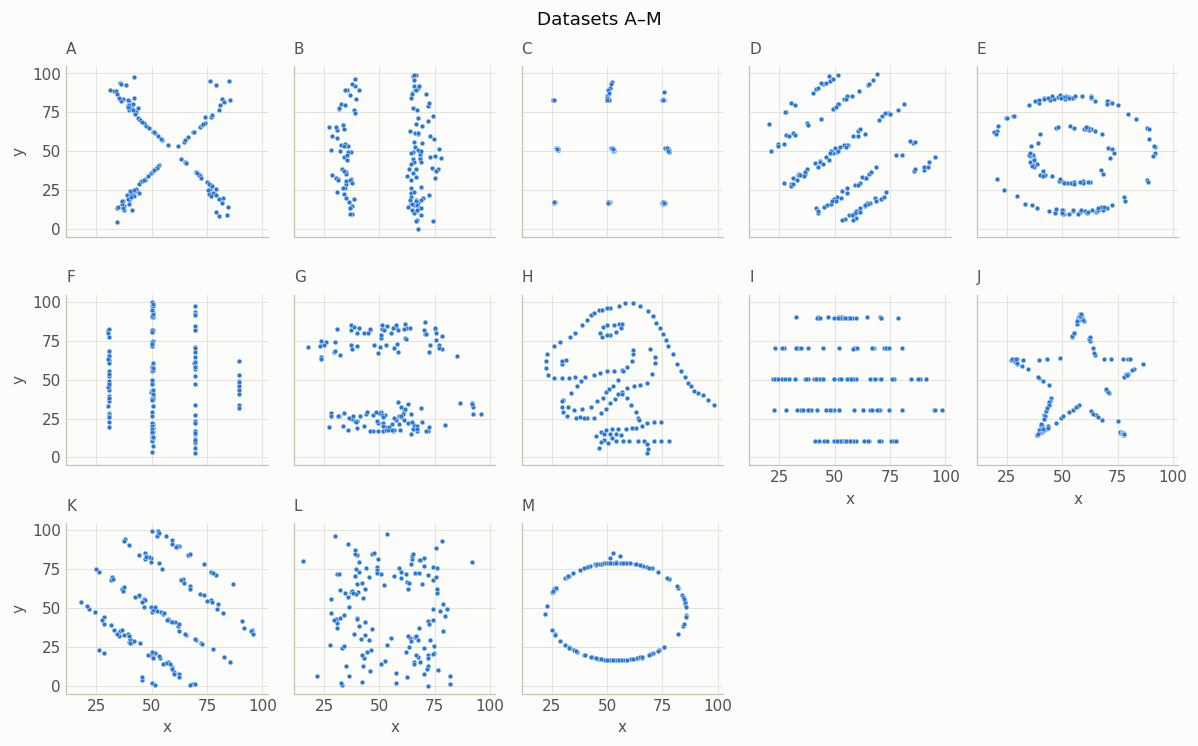

In [ ]:
# Run this cell
grid = sns.relplot(data=datasaurus, x="x", y="y", col="dataset", col_wrap=5, col_order=letters,
                   height=2.2, aspect=1, s=10)
grid.set_titles("{col_name}")
grid.figure.suptitle("Datasets A–M", y=1.02)
plt.show()

> ✏️ **Question 1.3.** Dataset M has a Pearson correlation close to zero. Would you describe `x` and `y` as unrelated? Explain using the scatter plot.

✍️ *Your answer:*
Given that the pearson corelation value is zzero, x and y have no linear relationship. This means that these two variables do not influence each other. However, they may be related in terms of causation. 

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

Summary statistics compress a dataset into a few numbers, and very different datasets can compress to the same numbers. A correlation close to 0 does not prove that two variables are unrelated. Look at the data before trusting a summary.

</details>

---

## 2. Initial regression analysis

A numerical result can conceal structure. We will now see what happens when we go straight to fitting a model: a simple linear regression predicting electricity access from GDP per capita. Before running it, record the relationship you expect to find.

### Expectations

> ✏️ **Question 2.1.** How do you expect electricity access to vary with GDP per capita? Explain your reasoning.

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 2.2.** Kenya, India, Bangladesh and Ghana had GDP per capita of roughly US\$1,800–2,300 in 2019. Would you expect similar electricity access in these countries? Why or why not?

✍️ *Your answer: type here, replacing this text.*

### Fitting the initial model

The data for this lab is *Global Data on Sustainable Energy*, a file published on [Kaggle](https://www.kaggle.com/datasets/anshtanwar/global-data-on-sustainable-energy) with one row per country and year from 2000 to 2020. The cell below loads it and fits a straight line predicting access from GDP per capita in 2019 (we check this choice of year later). It reports R², the share of the variation in access across these countries that the line captures.

In [ ]:
# Run this cell
raw_data = pd.read_csv(get_data("sustainable_energy.csv"))

access_raw = "Access to electricity (% of population)"
initial_rows = raw_data[raw_data["Year"] == 2019].dropna(subset=["gdp_per_capita", access_raw])

X = initial_rows[["gdp_per_capita"]]  # predictor: GDP per capita (current US$)
y = initial_rows[access_raw]          # outcome: access to electricity (% of population)

initial_model = LinearRegression()
initial_model.fit(X, y)
print("Countries:", len(initial_rows))
print(f"In-sample R²: {initial_model.score(X, y):.2f}")

Countries: 161
In-sample R²: 0.15


> ✏️ **Question 2.3.** Based on this R², how well does the model explain differences in electricity access between countries?

✍️ *Your answer: type here, replacing this text.*

### Interpreting the result

The cell below plots the observations with the fitted line.

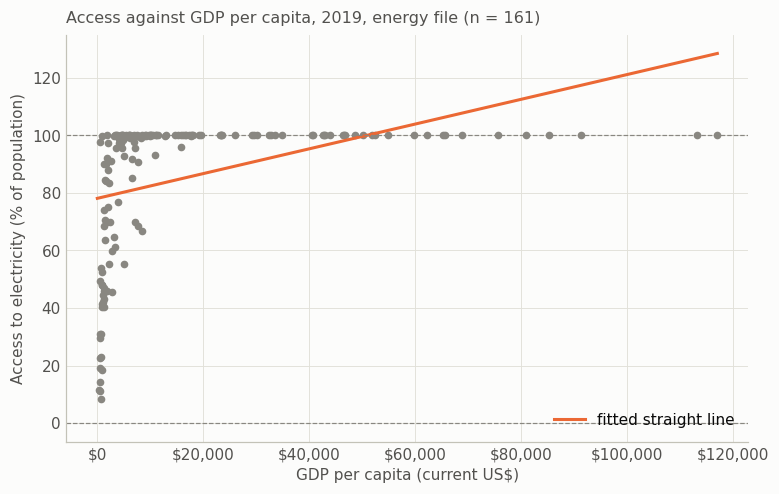

In [ ]:
# Run this cell
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(initial_rows["gdp_per_capita"], y, s=16, color=GREY)
line_x = np.linspace(0, initial_rows["gdp_per_capita"].max(), 200)
ax.plot(line_x, initial_model.predict(pd.DataFrame({"gdp_per_capita": line_x})), color=ORANGE,
        label="fitted straight line")
for level in [0, 100]:
    ax.axhline(level, color=GREY, linewidth=0.8, linestyle="--")
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel("GDP per capita (current US$)")
ax.set_ylabel("Access to electricity (% of population)")
ax.set_title(f"Access against GDP per capita, 2019, energy file (n = {len(initial_rows)})")
ax.legend(loc="lower right")
plt.show()

> ✏️ **Question 2.4.** Compare the fitted line with the observations. Where does it fail to describe their pattern?

✍️ *Your answer: type here, replacing this text.*

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

A model gives a number as soon as it runs, before we know whether it suits the data. A low R² for a straight line says that this line fits poorly; it does not say that the two variables are unrelated. Look at the observations before interpreting a score.

</details>

---

## 3. Understanding the dataset

The plot gives us a reason to reconsider the fitted relationship. Before changing the model, we also need to check what the measurements mean and which countries our comparison includes. The initial model used two columns of the file without checking either. We will read the file's documentation and decide what one row represents and which columns the question needs.

### Data dictionary

A data dictionary describes the columns in a dataset, including what they measure and their units. Read the dictionary below before answering the questions. It comes from the energy file's [Kaggle page](https://www.kaggle.com/datasets/anshtanwar/global-data-on-sustainable-energy), in the author's words, beside the column names as they appear in the file.

| Column in the file | Description in the dictionary |
|---|---|
| `Entity` | The name of the country or region for which the data is reported. |
| `Year` | The year for which the data is reported, ranging from 2000 to 2020. |
| `Access to electricity (% of population)` | The percentage of population with access to electricity. |
| `Access to clean fuels for cooking` | The percentage of the population with primary reliance on clean fuels. |
| `Renewable-electricity-generating-capacity-per-capita` | Installed renewable energy capacity per person. |
| `Financial flows to developing countries (US $)` | Aid and assistance from developed countries for clean energy projects. |
| `Renewable energy share in the total final energy consumption (%)` | Percentage of renewable energy in final energy consumption. |
| `Electricity from fossil fuels (TWh)` | Electricity generated from fossil fuels (coal, oil, gas) in terawatt-hours. |
| `Electricity from nuclear (TWh)` | Electricity generated from nuclear power in terawatt-hours. |
| `Electricity from renewables (TWh)` | Electricity generated from renewable sources (hydro, solar, wind, etc.) in terawatt-hours. |
| `Low-carbon electricity (% electricity)` | Percentage of electricity from low-carbon sources (nuclear and renewables). |
| `Primary energy consumption per capita (kWh/person)` | Energy consumption per person in kilowatt-hours. |
| `Energy intensity level of primary energy (MJ/$2017 PPP GDP)` | Energy use per unit of GDP at purchasing power parity (the dictionary gives 2011 dollars). |
| `Value_co2_emissions_kt_by_country` | Carbon dioxide emissions per person in metric tons (the column name says kilotonnes by country, so the two disagree). |
| `Renewables (% equivalent primary energy)` | Equivalent primary energy that is derived from renewable sources. |
| `gdp_growth` | Annual GDP growth rate based on constant local currency. |
| `gdp_per_capita` | Gross domestic product per person. |
| `Density\n(P/Km2)` | Population density in persons per square kilometer. |
| `Land Area(Km2)` | Total land area in square kilometers. |
| `Latitude` | Latitude of the country's centroid in decimal degrees. |
| `Longitude` | Longitude of the country's centroid in decimal degrees. |

The first rows of the file look like this.

In [ ]:
# Run this cell
raw_data.head(3)

,Entity,Year,Access to electricity (% of population),Access to clean fuels for cooking,Renewable-electricity-generating-capacity-per-capita,Financial flows to developing countries (US $),Renewable energy share in the total final energy consumption (%),Electricity from fossil fuels (TWh),Electricity from nuclear (TWh),Electricity from renewables (TWh),...,Primary energy consumption per capita (kWh/person),Energy intensity level of primary energy (MJ/$2017 PPP GDP),Value_co2_emissions_kt_by_country,Renewables (% equivalent primary energy),gdp_growth,gdp_per_capita,Density\n(P/Km2),Land Area(Km2),Latitude,Longitude
0,Afghanistan,2000,1.61,6.20,9.22,20000.00,44.99,0.16,0.00,0.31,...,302.59,1.64,760.00,NaN,NaN,NaN,60,652230.00,33.94,67.71
1,Afghanistan,2001,4.07,7.20,8.86,130000.00,45.60,0.09,0.00,0.50,...,236.89,1.74,730.00,NaN,NaN,NaN,60,652230.00,33.94,67.71
2,Afghanistan,2002,9.41,8.20,8.47,3950000.00,37.83,0.13,0.00,0.56,...,210.86,1.40,1030.00,NaN,NaN,179.43,60,652230.00,33.94,67.71


### Unit of analysis

> ✏️ **Question 3.1.** What does one row in this dataset represent?

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 3.2.** How many rows would you expect for each country if every year from 2000 to 2020 were included?

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 3.3.** Which two columns measure GDP per capita and electricity access?

✍️ *Your answer: type here, replacing this text.*

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

Read the documentation before the data. Record what one row represents, how many rows you expect, and which columns the question needs; the next section checks these expectations against the file.

</details>

---

## 4. Initial data checks

Before analysing the relationship between GDP per capita and electricity access, we need to check the data we will use. A file can load successfully while containing repeated records, missing measurements or numbers stored as text. These issues can affect which countries enter our comparison and the results we obtain.

We will focus on the six measurements below: GDP per capita and electricity access, together with four other features that may help us understand differences in access between countries. We will check how the columns have been imported, whether each country–year is recorded only once, what information is missing, and whether the recorded values make sense given their definitions.

| Column name | What it measures | Unit |
|---|---|---|
| `gdp_per_capita` | Gross domestic product divided by population | current US dollars per person |
| `electricity_access_pct` | Share of the population with access to electricity | % |
| `primary_energy_per_capita` | All primary energy used in the country per person, not only household electricity | kWh per person |
| `clean_cooking_access_pct` | Share of the population relying mainly on clean fuels for cooking | % |
| `renewable_energy_share_pct` | Renewable energy as a share of all final energy consumption, not only of electricity | % |
| `population_density` | Population per square kilometre of land | people per km² |

The cell below gives the columns these shorter names, which we will use throughout the lab.

In [ ]:
# Run this cell
short_names = {
    "gdp_per_capita": "gdp_per_capita",
    "Access to electricity (% of population)": "electricity_access_pct",
    "Primary energy consumption per capita (kWh/person)": "primary_energy_per_capita",
    "Access to clean fuels for cooking": "clean_cooking_access_pct",
    "Renewable energy share in the total final energy consumption (%)":
        "renewable_energy_share_pct",
    "Density\\n(P/Km2)": "population_density",
}
country_years = raw_data.rename(columns=short_names)  # a renamed copy; raw_data is unchanged
used = ["gdp_per_capita", "electricity_access_pct", "primary_energy_per_capita",
        "clean_cooking_access_pct", "renewable_energy_share_pct", "population_density"]

### Data types

> ✏️ **Question 4.1.** Inspect the dataset with `.shape` and `.info()`. Which of the six measurement columns need further attention, and why?
>
> <details><summary>Hint</summary><p>Run them on <code>country_years[used]</code>; <code>.shape</code> has no brackets.</p></details>

In [ ]:
# Question 4.1: write your code below
# Show the dimensions of country_years[used], then its .info() summary

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 4.2.** Generate a numerical summary of the six measurements using `.describe()`. Is every measurement included? Explain any omission using the data types you inspected.
>
> <details><summary>Hint</summary><p>Run it on <code>country_years[used]</code>.</p></details>

In [ ]:
# Question 4.2: write your code below
# Show the numerical summary of the six measurements

✍️ *Your answer: type here, replacing this text.*

A common way to convert text to numbers is [`pd.to_numeric()`](https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html). Setting `errors="coerce"` lets the conversion finish even when some values cannot be read, by replacing them with missing values.

Before converting, the cell below keeps a copy of the original density values, so that we can compare them with the result.

In [ ]:
# Run this cell
density_original = raw_data["Density\\n(P/Km2)"].copy()  # the original values, kept unchanged

> ✏️ **Question 4.3.** Use `pd.to_numeric()` with `errors="coerce"` to convert `density_original`, storing the result in `country_years["population_density_trial"]`. Did the conversion report a problem, and how many additional values became missing? The cell after yours compares the counts before and after.

In [ ]:
# Question 4.3: write your code where you see ___
country_years["population_density_trial"] = ___  # convert density_original

In [ ]:
# Run this cell
print("Missing before:", density_original.isna().sum())
print("Missing after:", country_years["population_density_trial"].isna().sum())

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 4.4.** The table below lists the countries whose density values became missing, with their original values. Are these values genuinely missing? What would we lose if we accepted this conversion?

In [ ]:
# Run this cell
newly_missing = density_original.notna() & country_years["population_density_trial"].isna()
lost = pd.DataFrame({"Entity": country_years.loc[newly_missing, "Entity"],
                     "original value": density_original[newly_missing]})
lost.groupby("Entity").agg(original_value=("original value", "first"),
                           years_lost=("original value", "size"))

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 4.5.** Remove the commas with `.str.replace(",", "", regex=False)` and convert again, storing the result in `density_clean`.

In [ ]:
# Question 4.5: write your code where you see ___
density_clean = ___  # remove the commas from density_original, then convert

The cell below checks that only the originally missing value is still missing.

In [ ]:
# Run this cell
print("Missing originally:", density_original.isna().sum())
print("Missing after correction:", density_clean.isna().sum())

The coerced conversion ran without any warning but discarded 105 usable measurements. Whenever an operation can replace values with missing data, check what it removed before using the result.

The cell below copies the corrected values into `country_years` and removes the trial column, so that later cells work even if your conversion did not.

In [ ]:
# Run this cell
country_years["population_density"] = pd.to_numeric(
    density_original.str.replace(",", "", regex=False))
country_years = country_years.drop(columns=["population_density_trial"], errors="ignore")

### Records and coverage

Repeated records can inflate counts and give some observations extra weight in an analysis. Each country–year combination should therefore appear only once.

> ✏️ **Question 4.6.** Check whether any country–year combination appears more than once.
>
> <details><summary>Hint</summary><p><code>.duplicated(subset=..., keep=False)</code> marks every copy, not only the later ones.</p></details>

In [ ]:
# Question 4.6: write your code where you see ___
repeated = ___  # True for every row whose Entity and Year appear more than once
print("Rows that share a country-year with another row:", repeated.sum())

The dictionary gives the dataset's overall date range, but individual countries may have different coverage.

> ✏️ **Question 4.7.** Does every country have a record for each year from 2000 to 2020? Identify those with incomplete coverage.
>
> <details><summary>Hint</summary><p><code>.groupby()</code> and <code>.nunique()</code>.</p></details>

In [ ]:
# Question 4.7: write your code where you see ___
years_per_country = ___  # the number of distinct years recorded for each country
years_per_country[years_per_country < 21].sort_values()

### Plausible values

Now that all six measurements are stored as numbers and the records have been checked, we can check whether the recorded values make sense given their definitions and units.

> ✏️ **Question 4.8.** Examine the minimum and maximum of each measurement. Are these consistent with what the measurement represents? Identify any values that need investigation.
>
> <details><summary>Hint</summary><p><code>.describe()</code>. The columns ending in <code>_pct</code> are percentages, so their values should lie between 0 and 100. For the others, refer to the definitions and units in the table at the start of this section.</p></details>

In [ ]:
# Question 4.8: write your code below
# Show the numerical summary of the six measurements

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 4.9.** Which country–year records have zero energy consumption per capita? Is this an isolated observation or a persistent pattern? What would you need to establish before changing these values?
>
> <details><summary>Hint</summary><p>Filter the records, then inspect the affected country's values across years.</p></details>

In [ ]:
# Question 4.9: write your code where you see ___
zero_energy = ___  # the rows of country_years where primary_energy_per_capita is 0
print(zero_energy["Entity"].value_counts())
zero_energy[["Entity", "Year", "primary_energy_per_capita"]]

✍️ *Your answer: type here, replacing this text.*

Other sources show that Tuvalu does use energy. IRENA reports a total energy supply of 113 TJ in 2017 and 141 TJ in 2022, and the World Bank records electricity access of 99.7% in 2019. The recorded zeros are therefore not real measurements, so the cell below records them as missing. Tuvalu stays in the file with its other measurements.

In [ ]:
# Run this cell
tuvalu_zeros = (country_years["Entity"].eq("Tuvalu")
                & country_years["primary_energy_per_capita"].eq(0))
country_years.loc[tuvalu_zeros, "primary_energy_per_capita"] = np.nan
print(tuvalu_zeros.sum(), "values recorded as missing")

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

Start with a new table's size, types and non-null counts, and check them against what the dictionary leads you to expect. Make sure numbers have been read as numbers, and check every conversion before and after: `errors="coerce"` would silently have removed every density value from five countries. Check that each record appears once and which country–years are absent, then compare each measurement's range with its definition. These checks are worth running even when they find nothing. Preserve the original value, and document how a questionable value is handled in the analysis.

</details>

---

## 5. Preparing the data for our question

Our research question asks how electricity access differs between countries with different GDP per capita. We care about differences between countries, not changes within a country over time, so we only need one observation per country, with every country measured in the same year. In this section we narrow the data to what our question needs and check that we have what we need to answer it.

Later we will also examine whether the other four measurements help describe differences in access. Keep this in mind when choosing a year.

### Choosing a year

> ✏️ **Question 5.1.** The chart below shows the percentage of missing values in each measurement for 2019 and 2020. Which year would you choose, and why?

In [ ]:
# Run this cell
missing = pd.DataFrame({
    year: country_years.loc[country_years["Year"] == year, used].isna().mean() * 100
    for year in [2019, 2020]
})

# rows and years reversed so the first feature, and 2019, are drawn at the top
chart = missing.rename(index=LABELS).iloc[::-1, ::-1]
ax = chart.plot.barh(figsize=(8, 3.5), color=[GREY, BLUE])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
handles, years = ax.get_legend_handles_labels()
ax.legend(handles[::-1], years[::-1], title="Year")
ax.set_xlim(0, 110)
ax.set_xlabel("Missing values (% of countries with a row that year)")
ax.set_title("Missing values by feature, 2019 and 2020")
plt.show()
missing.round(1)

✍️ *Your answer: type here, replacing this text.*

The cell below keeps the 2019 rows and the six measurements.

In [ ]:
# Run this cell
countries_2019 = (country_years.loc[country_years["Year"] == 2019, ["Entity"] + used]
                  .reset_index(drop=True))

### Handling missing values

The chart above shows that some measurements are missing in 2019. We will compare countries on all six measurements, so a country missing any of them cannot be placed in every comparison. The cell below counts the missing values in each measurement.

In [ ]:
# Run this cell
countries_2019.isna().sum()

A common way to handle missing values is to remove the rows that contain them with `.dropna()`, but removing rows also changes which countries our answer describes.

> ✏️ **Question 5.2.** Apply `.dropna()` to `countries_2019`, storing the result in `complete`. The cell after yours lists the countries it removed. Would excluding these countries affect our comparison?

In [ ]:
# Question 5.2: write your code where you see ___
complete = ___

In [ ]:
# Run this cell
excluded = countries_2019[~countries_2019["Entity"].isin(complete["Entity"])]
excluded[["Entity", "gdp_per_capita", "electricity_access_pct",
          "clean_cooking_access_pct", "renewable_energy_share_pct"]]

✍️ *Your answer: type here, replacing this text.*

### Filling gaps from another source

Missing values can sometimes be filled from another source. The World Bank publishes GDP per capita and electricity access for nearly every country. We will take both measurements from the World Bank for every country, not only for the gaps, so that all values come from the same release. This means every one of our countries must be found in its table.

The extract was taken from the World Bank's open data for this lab, from the release dated 8 October 2026; the region labels are the World Bank's own.

| Column | Description |
|---|---|
| `wb_name` | The economy's name, as the World Bank spells it. |
| `region` | The World Bank region, or `Aggregates` for a group of economies such as "World". |
| `gdp_per_capita_2019` | GDP per capita in 2019, current US\$ (indicator NY.GDP.PCAP.CD). |
| `access_2019` | Access to electricity (% of population) in 2019 (indicator EG.ELC.ACCS.ZS). |

The cell below loads the extract and removes the rows for groups of economies.

In [ ]:
# Run this cell
world_bank = pd.read_csv(get_data("world_bank_countries.csv"))
groups = (world_bank["region"] == "Aggregates").sum()
print(len(world_bank), "rows, of which", groups, "are groups of economies")
world_bank = world_bank[world_bank["region"] != "Aggregates"].reset_index(drop=True)
world_bank["region"] = world_bank["region"].str.strip()  # two region names end with a space
print(len(world_bank), "economies; names unique:", world_bank["wb_name"].is_unique)

> ✏️ **Question 5.3.** Use `.isin()` to check whether each country in `countries_2019` appears in `world_bank["wb_name"]`, storing the result in `found`, and list the countries that are not found.

>Turkey is among the ones not found. Search for it with `world_bank[world_bank["wb_name"].str.contains("Tur")]`. Does the World Bank really lack these countries? What explains the failed matches?

In [ ]:
# Question 5.3: write your code where you see ___
found = ___  # True where the country appears in world_bank["wb_name"]
print(countries_2019.loc[~found, "Entity"].tolist())

# Search the World Bank names for Turkey

✍️ *Your answer: type here, replacing this text.*

The other 13 countries differ in the same way. The cell below gives the World Bank spelling for each of the 14. The file's "Congo" is the Republic of the Congo, not the Democratic Republic of the Congo, whose name looks just as close.

In [ ]:
# Run this cell
name_fixes = {  # energy file spelling -> World Bank spelling
    "Bahamas": "Bahamas, The", "Congo": "Congo, Rep.", "Egypt": "Egypt, Arab Rep.",
    "Gambia": "Gambia, The", "Kyrgyzstan": "Kyrgyz Republic", "Nauru": "Naoero",
    "Puerto Rico": "Puerto Rico (US)", "Saint Kitts and Nevis": "St. Kitts and Nevis",
    "Saint Lucia": "St. Lucia",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Slovakia": "Slovak Republic", "Somalia": "Somalia, Fed. Rep.", "Turkey": "Turkiye",
    "Yemen": "Yemen, Rep.",
}
pd.Series(name_fixes, name="World Bank spelling").rename_axis("energy file spelling")

> ✏️ **Question 5.4.** Use `.replace(name_fixes)` on `countries_2019["Entity"]` to create a `wb_name` column, then check with `.isin()` that every country now matches.
>
> <details><summary>Hint</summary><p>Assign the result to <code>countries_2019["wb_name"]</code>; <code>.all()</code> checks that every value is <code>True</code>.</p></details>

In [ ]:
# Question 5.4: write your code where you see ___
countries_2019["wb_name"] = ___  # Entity, with the World Bank spellings from name_fixes

# Check that every wb_name now appears in world_bank["wb_name"]

### The analysis table

The cell below joins the two tables on `wb_name`, stopping if a name appears more than once on either side. It takes GDP per capita and access from the World Bank and keeps the energy file's values in separate columns. A country stays in the analysis only if it has all six measurements.

In [ ]:
# Run this cell
countries_2019["wb_name"] = countries_2019["Entity"].replace(name_fixes)  # in case yours differs
joined = countries_2019.merge(world_bank, on="wb_name", how="left",
                              validate="one_to_one", indicator=True)
gdp_filled = joined["gdp_per_capita"].isna() & joined["gdp_per_capita_2019"].notna()
other_four = ["primary_energy_per_capita", "clean_cooking_access_pct",
              "renewable_energy_share_pct", "population_density"]
has_required = joined[["gdp_per_capita_2019", "access_2019"] + other_four].notna().all(axis=1)
analysis = joined[has_required].rename(columns={
    "electricity_access_pct": "electricity_access_file",
    "gdp_per_capita": "gdp_per_capita_file",
    "access_2019": "electricity_access_pct", "gdp_per_capita_2019": "gdp_per_capita",
}).reset_index(drop=True)
print(len(analysis), "countries in the analysis")

The World Bank data brought back 10 of the 23 countries that `.dropna()` removed, giving 162 countries in the analysis. The 13 still excluded lack a measurement the extract does not provide, or have no 2019 GDP per capita in either source. They include South Sudan, which has the lowest electricity access in 2019, so our comparison lacks the bottom of the range. This is a limitation to report with our findings.

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

Narrow the data to what the question needs, and choose the year by the coverage of the measurements you intend to use. Before removing incomplete rows, count what you would lose and look at who it is, then check whether another source can fill the gaps. When combining sources, check that identifiers match before joining, fix them and check the fix, validate that each row matches once, and record everyone who is still left out as a limitation. Replacing values with another source's release changes existing values too, so keep the originals.

</details>

---

## 6. Distributions across countries

Before relating GDP per capita to electricity access, we look at how each measurement is spread across countries. How values are spread affects which comparisons and models make sense.

From here on we work with `analysis`, the table we built in the previous section: one row for each of the 162 countries in 2019, with all six measurements.

### Feature distributions

A histogram shows how a measurement is spread across countries. A distribution is right-skewed when most values are small and a few are much larger, giving a long tail to the right. Values can also pile up at a limit, such as 0% or 100% for a percentage.

> ✏️ **Question 6.1.** Plot a histogram of each of the six measurements (`gdp_per_capita`, `electricity_access_pct`, `primary_energy_per_capita`, `clean_cooking_access_pct`, `renewable_energy_share_pct` and `population_density`), which are listed in `used`. Which measurements are right-skewed, and which pile up at a limit?
>
> <details><summary>Hint</summary><p>In the loop, complete the plotting call with <code>sns.histplot(analysis[column], bins=25, ax=ax)</code>.</p></details>

In [ ]:
# Question 6.1: write your code where you see ___
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, column in zip(axes.flat, used):
    ___  # a histogram of analysis[column], drawn on ax
    ax.set(title=f"{LABELS[column]} (n = {analysis[column].count()})",
           xlabel=UNIT_ONLY[column])
    ax.xaxis.set_major_formatter(COMMAS)
    ax.locator_params(axis="x", nbins=5)
fig.suptitle("One value per country, 2019 (density: reference year not stated)")
plt.tight_layout()
plt.show()

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 6.2.** Look again at GDP per capita and electricity access. How might their distributions help explain why the straight line we fitted at the start described the relationship poorly?

✍️ *Your answer: type here, replacing this text.*

### Logarithmic representations

A logarithmic scale is one way to handle right skew. On a logarithmic scale, equal distances are equal ratios rather than equal differences, so the step from 1,000 to 10,000 is the same length as the step from 10,000 to 100,000. A logarithm is defined only for positive numbers, so a zero or negative value has none.

> ✏️ **Question 6.3.** Use `np.log10()` to add log columns for `gdp_per_capita`, `primary_energy_per_capita` and `population_density`, named `log_gdp_per_capita`, `log_primary_energy_per_capita` and `log_population_density`. The cell after yours plots the three measurements on a logarithmic scale. What can you see more clearly than in the original histograms?

In [ ]:
# Question 6.3: write your code where you see ___
for feature in ["gdp_per_capita", "primary_energy_per_capita", "population_density"]:
    analysis["log_" + feature] = ___  # the base-10 logarithm of analysis[feature]

In [ ]:
# Run this cell
skewed = ["gdp_per_capita", "primary_energy_per_capita", "population_density"]
for feature in skewed:  # recreated in case yours differs
    analysis["log_" + feature] = np.log10(analysis[feature])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, feature in zip(axes, skewed):
    sns.histplot(analysis[feature], bins=25, log_scale=True, ax=ax, color=GREY)
    ax.set(title=f"{LABELS[feature]}, log scale (n = {analysis[feature].count()})",
           xlabel=UNIT_ONLY[feature])
    ax.xaxis.set_major_formatter(COMMAS)
plt.tight_layout()
plt.show()

✍️ *Your answer: type here, replacing this text.*

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

Describe the shape of each distribution before relating measurements to each other. A right-skewed measurement squeezes most countries into a small part of an ordinary axis; a logarithmic scale spreads them out by turning equal steps into equal ratios, and it can only be taken of positive values. A measurement that piles up at a limit, as access does at 100%, needs a model that can level off.

</details>

---

## 7. Relationships between variables

Before revisiting the model, we look at the relationships it will describe. We examine the shape of the relationship between GDP per capita and electricity access, how much countries vary around it, which other measurements are related to access, and how those measurements relate to each other.

### The main relationship

> ✏️ **Question 7.1.** Plot electricity access against GDP per capita, with GDP per capita on a logarithmic axis. Describe how access changes as GDP per capita rises.
>
> <details><summary>Hint</summary><p><code>plt.scatter(x, y)</code>, then <code>plt.xscale("log")</code>.</p></details>

In [ ]:
# Question 7.1: write your code where you see ___
___  # a scatter plot of access (y) against GDP per capita (x)
___  # make the x-axis logarithmic
plt.gca().xaxis.set_major_formatter(dollars)
plt.xlabel("GDP per capita (current US$, log scale)")
plt.ylabel("Access to electricity (%)")
plt.show()

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 7.2.** The table below shows Kenya, India, Bangladesh and Ghana, which have almost the same GDP per capita. You made a prediction about them at the start. How much does their electricity access differ, and what does this say about using GDP per capita to predict a single country's access?

In [ ]:
# Run this cell
four = analysis[analysis["Entity"].isin(["Kenya", "India", "Bangladesh", "Ghana"])]
columns = ["Entity", "gdp_per_capita", "electricity_access_pct"]
four.sort_values("gdp_per_capita")[columns].round(1)

✍️ *Your answer: type here, replacing this text.*

### Summarising the relationship

Two correlation coefficients are in common use. Pearson's correlation coefficient measures how closely the points follow a straight line. Spearman's rank correlation coefficient is calculated from the countries' ranks, so it measures how consistently one variable rises as the other rises, whether or not in a straight line. Both are positive when the two variables rise together and negative when one falls as the other rises.

> ✏️ **Question 7.3.** Use `.corr()` to calculate Pearson's correlation between electricity access and GDP per capita, and between access and log GDP per capita. Repeat both with `method="spearman"`. Why is Pearson's coefficient for GDP per capita so much lower than Spearman's, and why does taking logs change one coefficient but not the other?

In [ ]:
# Question 7.3: write your code where you see ___
access = analysis["electricity_access_pct"]
print("Pearson, GDP per capita:", round(___, 2))
print("Pearson, log GDP per capita:", round(___, 2))
print("Spearman, GDP per capita:", round(___, 2))
print("Spearman, log GDP per capita:", round(___, 2))

✍️ *Your answer: type here, replacing this text.*

### Other measurements and electricity access

GDP per capita leaves large differences in access between countries, and the other measurements may describe some of them. A pair plot draws a scatter plot for every pair of measurements, with each measurement's histogram on the diagonal. The cell below lists the six measurements to compare, using the log versions of the three right-skewed ones.

In [ ]:
# Run this cell
compared = ["electricity_access_pct", "log_gdp_per_capita", "log_primary_energy_per_capita",
            "clean_cooking_access_pct", "renewable_energy_share_pct", "log_population_density"]

> ✏️ **Question 7.4.** Create a pair plot of the six measurements in `compared`. Look at the row for electricity access. Which measurements rise with access, which fall, and which show little relationship?
>
> <details><summary>Hint</summary><p><code>sns.pairplot(analysis[compared])</code>.</p></details>

In [ ]:
# Question 7.4: write your code where you see ___
___  # a pair plot of analysis[compared]
plt.show()

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 7.5.** Renewable energy share measures renewables as a share of all final energy consumption, not only electricity. How could a country have a high renewable energy share but low electricity access?

✍️ *Your answer: type here, replacing this text.*

### Relationships between predictors

In the next section we will put several of these measurements into one model. When a model includes several predictors, it estimates each one's association with access after allowing for the others. A correlation heatmap shows the coefficient for every pair of measurements as a coloured grid, which makes the strongest relationships easy to find. A coefficient's strength is its size ignoring the sign, and because Pearson's coefficient measures closeness to a straight line, a strong value is worth checking against its panel in the pair plot.

> ✏️ **Question 7.6.** Create a heatmap of the Pearson correlations between the six measurements in `compared`. Which two predictors are most strongly correlated? Check their panel in the pair plot. Could a model tell their separate associations with access apart? Why or why not?
>
> <details><summary>Hint</summary><p><code>sns.heatmap(analysis[compared].corr(), annot=True, fmt=".2f")</code>.</p></details>

In [ ]:
# Question 7.6: write your code where you see ___
___  # a heatmap of the Pearson correlations of analysis[compared], with the values shown
plt.show()

✍️ *Your answer: type here, replacing this text.*

Strong linear relationships among predictors are called multicollinearity. When two predictors usually rise and fall together, the data contain few countries in which one changes while the other stays the same, so a model cannot easily tell how much of their shared association with access belongs to each. As one standard textbook puts it, "it can be difficult to separate out the individual effects of collinear variables on the response".

<small>Source: James, Witten, Hastie and Tibshirani, [*An Introduction to Statistical Learning*](https://www.statlearning.com/), 2nd edition, section 3.3.3, p. 111.</small>

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

A model can only describe what the data show. Its form must match the shape of the relationship, it cannot explain variation its predictors do not carry, it cannot separate predictors that move together, and its results mean only what its measurements mean. Pearson's coefficient measures closeness to a straight line and can change with a logarithm; Spearman's uses only ranks and does not.

</details>

---

## 8. Revisiting the model

In the previous section, access levelled off near 100%, countries with similar GDP per capita differed widely in access, and GDP per capita moved closely with energy use. Each of these observations shapes a step below.

All the models below use the same countries, so their fits can be compared directly. Each R² is in-sample, describing the countries used to fit the model rather than how well it would predict others. The first line has the same form as the opening model but uses the World Bank figures and a different set of countries, so its R² need not equal 0.15.

In [ ]:
# Run this cell
print(len(analysis), "countries in every model below")

### Shape and bounds

The rise in access was easier to see on a logarithmic GDP per capita axis. Changing an axis changes only how we view the points, but fitting a line to log GDP per capita changes the relationship the model describes. Both lines below are drawn on a logarithmic axis, where a line fitted to GDP per capita itself looks curved.

> ✏️ **Question 8.1.** The cell below fits a straight line to GDP per capita. Use `fit()` to add a second straight line fitted to log GDP per capita, then compare the two lines and their R² values. Which describes the relationship better, and why?
>
> <details><summary>Hint</summary><p><code>fit(analysis, ["log_gdp_per_capita"], model="line")</code>.</p></details>

In [ ]:
# Question 8.1: write your code where you see ___
lines = {
    "straight line in GDP per capita (curved on this axis)":
        fit(analysis, ["gdp_per_capita"], model="line"),
    "straight line in log GDP per capita":
        ___,
}
plot_fitted_models(analysis, lines)

✍️ *Your answer: type here, replacing this text.*

> ✏️ **Question 8.2.** Look at where the line in log GDP per capita goes at the highest GDP per capita. Is a straight line the right kind of model for electricity access? Why or why not?

✍️ *Your answer: type here, replacing this text.*

A model for a percentage should level off and stay between 0 and 100%. An S-curve, or logistic curve, rises steeply in the middle and levels off towards 0 and 100% without passing either. In log GDP per capita it has the form

$$\text{access} = \frac{100}{1 + e^{-(b_0 + b_1 \log_{10}(\text{GDP per capita}))}}$$

where $b_0$ and $b_1$ are estimated from the data. However large or small $b_0 + b_1 \log_{10}(\text{GDP per capita})$ becomes, the fraction stays between 0 and 100. The cell below fits an S-curve in log GDP per capita and draws it with the two straight lines.

> ✏️ **Question 8.3.** What does the S-curve do differently from the straight lines at the ends of the observed range? How does its R² compare with the 0.15 from the straight line at the start, and what explains the difference?

In [ ]:
# Run this cell
s_curve = fit(analysis, ["log_gdp_per_capita"], model="s-curve")
models = {**lines, "S-curve in log GDP per capita": s_curve}
plot_fitted_models(analysis, models)

✍️ *Your answer: type here, replacing this text.*

The S-curve is one simple shape with these properties, not the only possible one.

### Where GDP per capita falls short

A residual is a country's observed access minus the access the model predicts, in percentage points. A negative residual means the model overestimates access; a positive residual means it underestimates. If a model captures what matters, its residuals scatter around zero with no pattern.

> ✏️ **Question 8.4.** Calculate each country's residual from the S-curve, storing it in `analysis["residual"]`. The cell after yours plots the residuals by region. In which regions does the model consistently overestimate or underestimate access?
>
> <details><summary>Hint</summary><p>Subtract <code>s_curve.predict(analysis)</code> from <code>analysis["electricity_access_pct"]</code>.</p></details>

In [ ]:
# Question 8.4: write your code where you see ___
analysis["residual"] = ___  # observed access minus the S-curve's prediction

In [ ]:
# Run this cell
analysis["residual"] = analysis["electricity_access_pct"] - s_curve.predict(analysis)  # in case yours differs
by_region = plot_region_residuals(
    analysis, title="Residuals of the S-curve in log GDP per capita, by region")
by_region.round(1)

✍️ *Your answer: type here, replacing this text.*

### Describing what GDP per capita misses

The other four measurements may describe some of the differences that GDP per capita misses. The cell below fits four separate models, each containing log GDP per capita and one other measurement, so each row of the table can be compared with the first row, which contains log GDP per capita only. Each model is still an S-curve, so its predictions stay between 0 and 100%.

> ✏️ **Question 8.5.** Compare each model with the first row. Which added measurement brings Sub-Saharan Africa's median residual closest to zero, and which brings South Asia's closest? Which raises R² the most?

In [ ]:
# Run this cell
others = ["log_primary_energy_per_capita", "clean_cooking_access_pct",
          "renewable_energy_share_pct", "log_population_density"]
added = add_one_at_a_time(analysis, ["log_gdp_per_capita"], others,
                          regions=["Sub-Saharan Africa", "South Asia"],
                          base_label="log GDP per capita only", base_name="log GDP per capita",
                          include_all=False)
added.round(2)

✍️ *Your answer: type here, replacing this text.*

### Overlapping predictors

In the previous section, GDP per capita, energy use and clean cooking moved closely together. The cell below compares the model with all five measurements with versions that leave out GDP per capita or energy use.

> ✏️ **Question 8.6.** Compare R² for the full model with and without GDP per capita, and without energy use. Does the small change mean GDP per capita tells us little about access? Why or why not?

In [ ]:
# Run this cell
explanatory = ["log_gdp_per_capita"] + others
joint = {
    "all five measurements": explanatory,
    "without log GDP per capita": [v for v in explanatory if v != "log_gdp_per_capita"],
    "without log energy use": [v for v in explanatory if v != "log_primary_energy_per_capita"],
}
r_squared_table(analysis, joint)

✍️ *Your answer: type here, replacing this text.*

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

Exploring the data showed how to revisit the first model, with a logarithm for the skewed GDP per capita and a curve that levels off for a percentage. The first model's low score came from a model that did not match the data, not from GDP per capita being uninformative. Look at where a model misses, because a pattern in the residuals means something it does not include matters. When predictors overlap, removing one can change the fit very little even though it is clearly related to the outcome, so judge it from its own model.

</details>

---

## 9. Findings and limitations

We can now answer the research question using the relationships we observed, the model's fit and the differences it misses.

> ✏️ **Question 9.1.** Answer the research question in a short paragraph. Say how much GDP per capita tells us about electricity access, where it falls short, and one limitation of the analysis.
>
> <details><summary>Pointers</summary><ul><li>How much: the shape of the relationship, and the S-curve's R² compared with the straight line at the start.</li><li>Where it falls short: the four countries with almost the same GDP per capita, and the regions whose residuals sit mostly on one side of zero.</li><li>What describes the rest: which added measurement moved each region's residual, and why removing GDP per capita from the full model does not mean it tells us little.</li><li>Limitations: which countries and year the data cover, how countries are weighted, who was excluded, and whether the results show causes.</li></ul></details>

✍️ *Your answer: type here, replacing this text.*

<details>
<summary><strong>Key points</strong> (open once you have answered the questions)</summary>

A supported conclusion says what the evidence shows, for which countries and year, and what it cannot show. Checking the data did not prove the answer true; it made the answer better supported and its limits clearer.

</details>